# Introduction to Machine Learning -- MC886A/MO444A
# Assignment 3 - Neural Networks, Inductive Bias and Distribution Shift

**Professor:** Marcelo da Silva Reis

**PED:** Heigon Soldera

In [ ]:
# Enter your name and RA number below.
print("Student 1", "|", "RA1")
print("Student 2", "|", "RA2")
# Remove the line below if your group has only two members.
print("Student 3", "|", "RA3")

Student 1 | RA1
Student 2 | RA2
Student 3 | RA3


---

## Objective

In Assignment 2 you saw that the model selected by cross-validation on the training distribution is not
necessarily the most robust one when the test distribution changes. There, the assumption we varied was the
**penalty** of a linear model. In this assignment we vary the **architecture**.

A multilayer perceptron (MLP) and a convolutional neural network (CNN) can both fit a training set almost
perfectly, but they do it under different assumptions about the input, their **inductive biases**:
- an MLP gives every pixel position its own weight and knows nothing about which pixels are neighbors;
- a CNN detects local patterns with small filters that are shared across all positions, and combines them
  hierarchically.

When several hypotheses explain the training data equally well, these assumptions decide which one the network
learns, and the difference only shows up when the test distribution changes. For example, a classifier of
histopathology images can recognize a type of tissue from the shape and the arrangement of its cells, which are the
same in every hospital, or from the exact colors produced by the staining protocol of the hospital where the
training images were acquired. Both solutions fit the training set, but only one of them survives a new hospital.

The goal of this assignment is to test, with controlled experiments, which structural assumptions and which training
choices help a neural network generalize to a clinical center it has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Answers can be written in English or Portuguese.

2. Use data visualization as a primary tool for understanding. Inspect the training data, the transformed inputs, and
   model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves as a reference. Modifications are allowed, including changes to functions and the
   introduction of new components. Code clarity and organization are required. The hands-on of Lecture 18 (Deep
   Learning with PyTorch) contains reference implementations of the training loop, of an MLP, of a CNN and of data
   augmentation.

4. We recommend running this notebook on a GPU, for example on Google Colab (GPU runtime) or on a local GPU.

5. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for
   **implementation support**. Their use for interpreting, analyzing, or discussing experimental results is
   discouraged. Submissions must include:
   - A declaration of which models were used.
   - The prompts that generated any incorporated code.

6. Do not hesitate to reach out to the PED/PAD via Discord.

### Experiment structure

Each experiment must follow the structure below:

1. **Question**: the empirical question guiding the exploration.
2. **Hypothesis**: a falsifiable answer to the question that makes a concrete, measurable prediction.
3. **Design**: justify why the proposed experiment can test the hypothesis. Focus on the reasoning, not on how the
   code works.
4. **Results**: run the experiment and report the metrics.
5. **Discussion**: interpret the results in terms of the hypothesis. Explicitly state whether the results support or
   contradict it, and why.

A hypothesis must be **falsifiable**: the proposed experiment must be capable of providing evidence *against* it.
Statements such as "the model is complex enough" or "the features are informative" do not qualify.

A negative result is not a failure: a well-reasoned experiment that contradicts the hypothesis is graded as highly as
one that confirms it, provided the interpretation is honest and coherent.

For Experiment 1, the question and hypothesis are given. Your task is to complete the missing code, write the design
justification, and discuss the results.
For Experiments 2-4, only the question is given. You must state the hypothesis and discuss the results; in
Experiments 2 and 3 you also justify the design, and in Experiment 4 you choose and evaluate the final model.

### Evaluation protocol

Throughout this assignment, **ID** (*in-distribution*) refers to patches from the same clinical center as the training
set, and **OOD** (*out-of-distribution*) to patches from a different center, which the model never sees during
training.

- **Model selection** (number of epochs, hyperparameters, early stopping, choice of the final model) uses only the
  **ID validation** split.
- The **OOD validation** split is used to *measure* the generalization gap in Experiments 1-4, never to choose
  hyperparameters or models.
- The **OOD test** split is used **only once**, at the end of Experiment 4. Do not look at its images or metrics
  before that.

In [1]:
import copy
import os
import random
import time
import urllib.request

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import balanced_accuracy_score, confusion_matrix

import matplotlib.pyplot as plt
from IPython.display import display

# ── Reproducibility ────────────────────────────────────────────────────────────
# Do not change this seed. Re-run the notebook from scratch before submitting.
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)
torch.backends.cudnn.deterministic = True   # reproducible results on the GPU
torch.backends.cudnn.benchmark = False

DEVICE: str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


---

## Dataset — PathMNIST

Histopathology is the study of thin sections of tissue under a microscope, often to detect disease. The most common
technique stains the section with hematoxylin and eosin (H&E): hematoxylin colors the cell nuclei purple-blue, and
eosin colors the cytoplasm and the extracellular matrix pink, so the pathologist can tell the structures apart.

We use **PathMNIST**, from the [MedMNIST v2](https://medmnist.com/) benchmark, in its 64×64 version. Each sample is a
64×64 RGB patch of an H&E-stained section of colorectal tissue, labeled with one of **9 tissue classes**:

| Label | Tissue |
|---|---|
| 0 | adipose |
| 1 | background |
| 2 | debris |
| 3 | lymphocytes |
| 4 | mucus |
| 5 | smooth muscle |
| 6 | normal colon mucosa |
| 7 | cancer-associated stroma |
| 8 | colorectal adenocarcinoma epithelium |

The patches come from two datasets of the same study (Kather et al., 2019):
- the training and validation patches come from **NCT-CRC-HE-100K**;
- the test patches come from **CRC-VAL-HE-7K**, acquired at a **different clinical center**, with other patients.

Each center has its own staining protocol, scanner and population of patients, so the patches of the new center
differ from the training ones in ways that have nothing to do with the tissue class.

We use the following splits:

| Split | Source | Patches | Role in this assignment |
|---|---|---|---|
| `train` | NCT-CRC-HE-100K | 89,996 | Training |
| `id_val` | NCT-CRC-HE-100K | 10,004 | **ID validation**: early stopping and model selection |
| `ood_val` | CRC-VAL-HE-7K, first half | 3,590 | **OOD validation**: measures the generalization gap |
| `ood_test` | CRC-VAL-HE-7K, second half | 3,590 | **OOD test**: used only once, at the end of Experiment 4 |

The `id_val` patches were drawn at random from the same dataset as the training patches. The official test set of
PathMNIST is split in two halves, stratified by class, with the seed of this notebook. The two halves may contain
patches of the same patients, so they are not fully independent: `ood_test` protects the final result against
choices made *because* a model did well on `ood_val`, but not against everything the two halves have in common.

**Metrics.** We report the accuracy and the **balanced accuracy**, the mean of the recalls of the 9 classes
(`sklearn.metrics.balanced_accuracy_score`). Unlike the accuracy, the balanced accuracy does not change when only
the proportions of the classes change, which will matter in Experiment 4. The **ID–OOD gap**, the balanced accuracy
on `id_val` minus the balanced accuracy on `ood_val`, is the main measure of generalization to the new center.

The next cell downloads the 64×64 version of PathMNIST (about 1 GB, only once) from the
[MedMNIST repository on Zenodo](https://zenodo.org/records/10519652). Alternatively, you can download the data of this
assignment from our Google Classroom page: place the file `pathmnist_64.npz` in a folder named `data`, inside the
working directory of the notebook (on Colab, `/content/data`), and the cell will not download it again. You can also
install the `medmnist` package and use `medmnist.PathMNIST(split=..., size=64, download=True)`.

In [2]:
DATA_DIR = "data"
DATA_PATH = os.path.join(DATA_DIR, "pathmnist_64.npz")
DATA_URL = "https://zenodo.org/records/10519652/files/pathmnist_64.npz"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_PATH):                    # download only once
    print("Downloading PathMNIST 64x64 (about 1 GB)...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

CLASSES = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle",
           "normal colon mucosa", "cancer-associated stroma", "colorectal adenocarcinoma epithelium"]

with np.load(DATA_PATH) as f:
    # Images stay as uint8 (N, 3, 64, 64) to save memory; they are converted to float one batch at a time.
    X_train = torch.from_numpy(f["train_images"]).permute(0, 3, 1, 2).contiguous()
    y_train = torch.from_numpy(f["train_labels"]).long().squeeze(1)
    X_id_val = torch.from_numpy(f["val_images"]).permute(0, 3, 1, 2).contiguous()
    y_id_val = torch.from_numpy(f["val_labels"]).long().squeeze(1)
    X_external = torch.from_numpy(f["test_images"]).permute(0, 3, 1, 2).contiguous()
    y_external = torch.from_numpy(f["test_labels"]).long().squeeze(1)

In [3]:
def stratified_split(y: torch.Tensor, fraction: float, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    # Splits the indices of y in two parts, with `fraction` of each class in the first part.
    first, second = [], []
    for c in np.unique(y.numpy()):
        idx = rng.permutation(np.flatnonzero(y.numpy() == c))
        cut = round(fraction * len(idx))
        first.append(idx[:cut])
        second.append(idx[cut:])
    return np.sort(np.concatenate(first)), np.sort(np.concatenate(second))


rng = np.random.default_rng(seed)

# The external center is split in two halves: OOD validation and OOD test.
ood_val_idx, ood_test_idx = stratified_split(y_external, 0.5, rng)
X_ood_val, y_ood_val = X_external[ood_val_idx], y_external[ood_val_idx]
X_ood_test, y_ood_test = X_external[ood_test_idx], y_external[ood_test_idx]
del X_external, y_external

SPLITS = {
    "train": (X_train, y_train),
    "id_val": (X_id_val, y_id_val),
    "ood_val": (X_ood_val, y_ood_val),
    "ood_test": (X_ood_test, y_ood_test),   # do not use before the end of Experiment 4
}
for name, (X, y) in SPLITS.items():
    print(f"{name:8s}: {tuple(X.shape)}, {X.dtype}")

train   : (89996, 3, 64, 64), torch.uint8
id_val  : (10004, 3, 64, 64), torch.uint8
ood_val : (3590, 3, 64, 64), torch.uint8
ood_test: (3590, 3, 64, 64), torch.uint8


### Preprocessing

The networks of this assignment are trained from scratch, so we standardize each color channel with the mean and the
standard deviation of the **training split only** (no leakage), and apply the same statistics to every split.

`Preprocess` turns a batch of uint8 images into the model input, on the device. It also accepts a `color_fn`, a
transformation of the colors applied before the standardization (Experiment 3), and, during training, an `augment`
function applied to the RGB images in [0, 1] (Experiments 2 and 3).

In [4]:
def to_unit(x: torch.Tensor) -> torch.Tensor:
    # uint8 batch (N, 3, H, W) -> float in [0, 1], on the device.
    return x.to(DEVICE, non_blocking=True).float().div(255)


class Preprocess:
    # uint8 batch -> [augmentation] -> [color transformation] -> standardization with training statistics.

    def __init__(self, color_fn=None):
        self.color_fn = color_fn if color_fn is not None else (lambda x: x)
        total, total_sq, n_pixels = 0.0, 0.0, 0
        for i in range(0, len(X_train), 5_000):          # statistics of the TRAINING split only
            x = self.color_fn(to_unit(X_train[i:i + 5_000])).double()
            total = total + x.sum(dim=(0, 2, 3))
            total_sq = total_sq + (x ** 2).sum(dim=(0, 2, 3))
            n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
        mean = total / n_pixels
        self.mean = mean.float().view(1, -1, 1, 1)
        self.std = (total_sq / n_pixels - mean ** 2).sqrt().float().view(1, -1, 1, 1)

    def __call__(self, x: torch.Tensor, augment=None) -> torch.Tensor:
        x = to_unit(x)
        if augment is not None:                          # training only
            x = augment(x)
        return (self.color_fn(x) - self.mean) / self.std


rgb = Preprocess()
print("channel mean:", rgb.mean.flatten().cpu().numpy().round(3), "| channel std:", rgb.std.flatten().cpu().numpy().round(3))

channel mean: [0.741 0.533 0.706] | channel std: [0.14  0.195 0.139]


---

## Data Exploration

Before starting the experiments, take a moment to explore the dataset and understand its structure. Below, we show
random patches of each class, from the training center and from the new center (OOD validation).

The goal is to have a better idea of the task, and of what problems are already recognizable without training any
model: class balance, differences between the two centers, which information is available in a patch, which
transformations do not change the class.

**Do not look at the OOD test split (`ood_test`) in this section.**

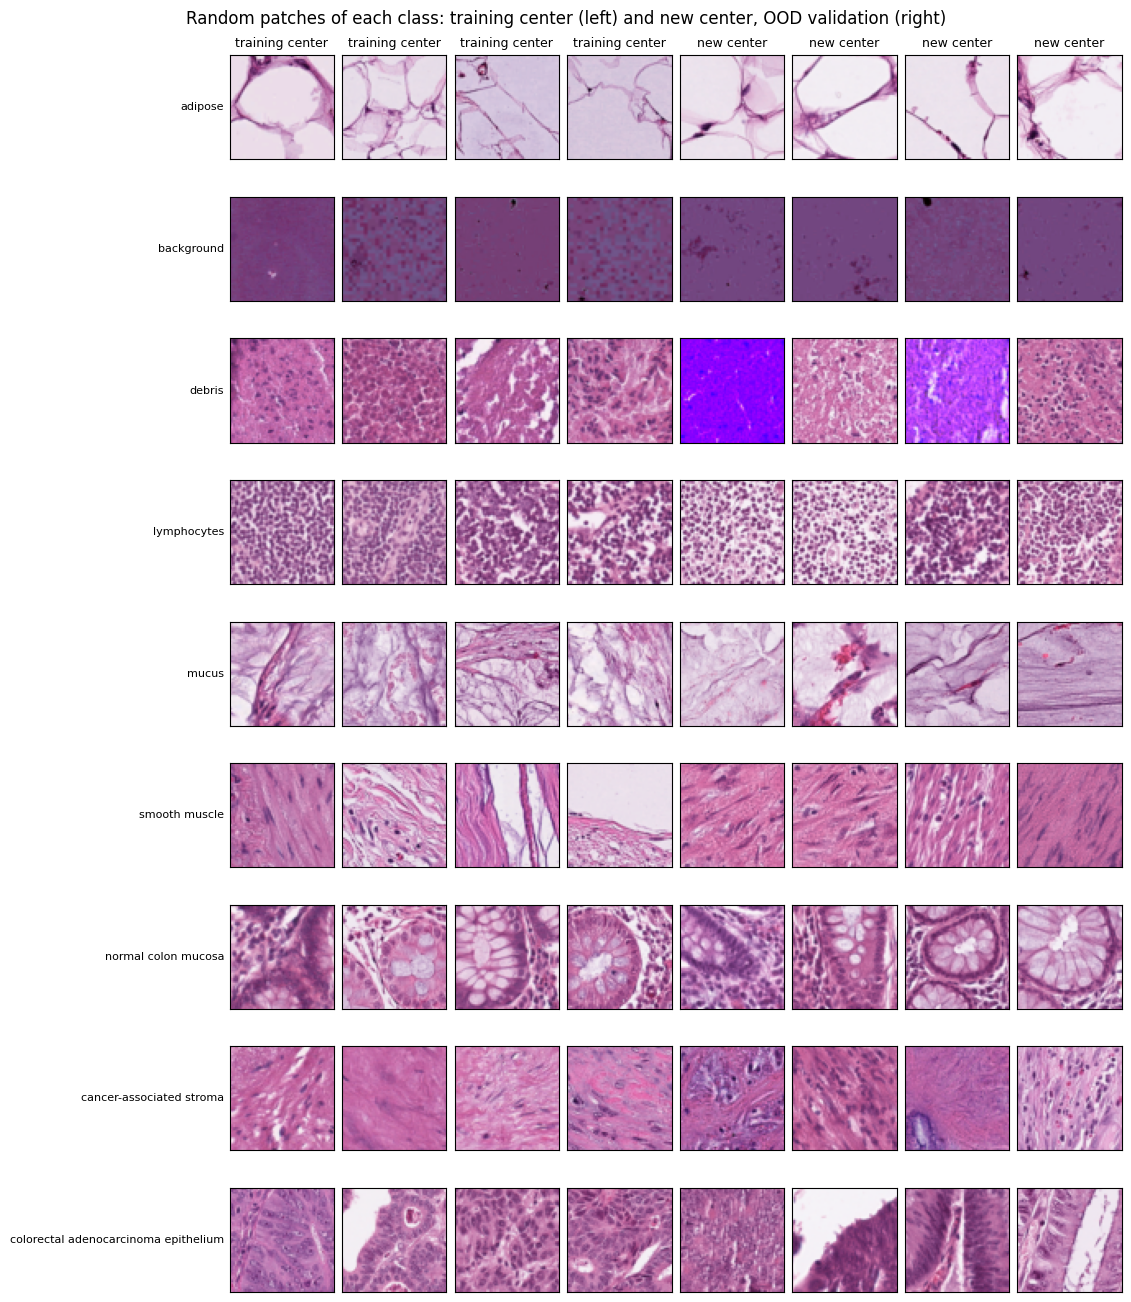

In [5]:
n = 4
rng = np.random.default_rng(seed)

fig, axs = plt.subplots(len(CLASSES), 2 * n, figsize=(2 * n * 1.4, len(CLASSES) * 1.45), constrained_layout=True)
for c, name in enumerate(CLASSES):
    for j, split in enumerate(["train", "ood_val"]):
        X, y = SPLITS[split]
        for k, i in enumerate(rng.choice(np.flatnonzero(y.numpy() == c), size=n, replace=False)):
            ax = axs[c, j * n + k]
            ax.imshow(X[i].permute(1, 2, 0).numpy())
            ax.set_xticks([])
            ax.set_yticks([])
            if c == 0:
                ax.set_title("training center" if split == "train" else "new center", fontsize=9)
    axs[c, 0].set_ylabel(name, fontsize=8, rotation=0, ha="right", va="center")

fig.suptitle("Random patches of each class: training center (left) and new center, OOD validation (right)", fontsize=12)
plt.show()

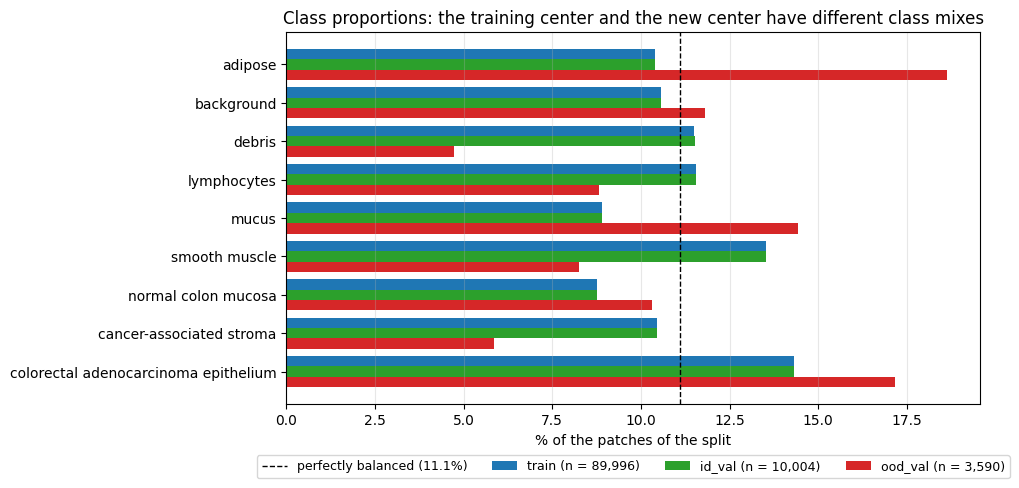

,train,id_val,ood_val,ood_val / train
adipose,10.4,10.4,18.6,1.79
background,10.6,10.6,11.8,1.12
debris,11.5,11.5,4.7,0.41
lymphocytes,11.6,11.6,8.8,0.76
mucus,8.9,8.9,14.4,1.62
smooth muscle,13.5,13.5,8.2,0.61
normal colon mucosa,8.8,8.8,10.3,1.18
cancer-associated stroma,10.4,10.4,5.8,0.56
colorectal adenocarcinoma epithelium,14.3,14.3,17.2,1.20


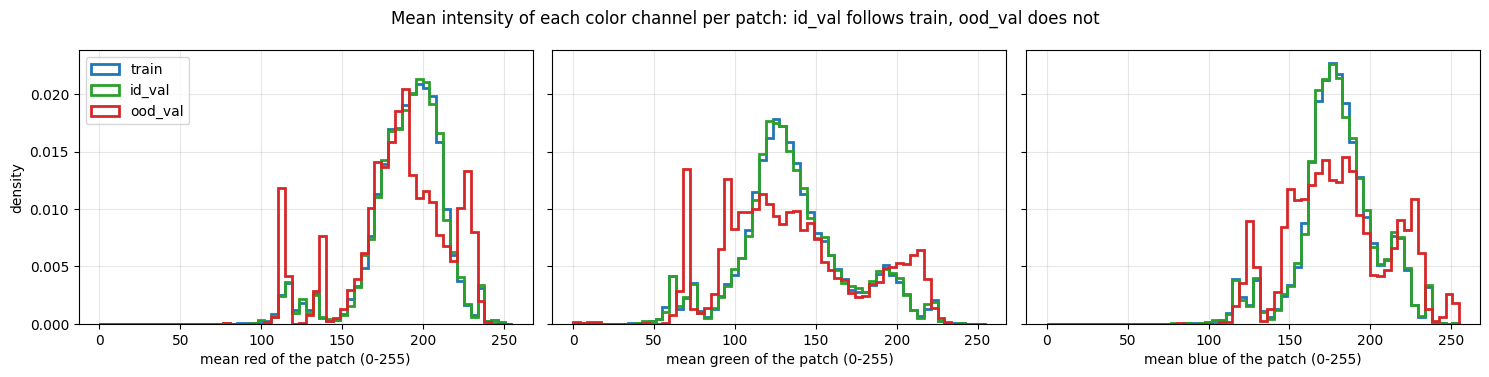

,mean R,mean G,mean B
train,188.800003,135.899994,180.000000
id_val,189.100006,136.300003,180.300003
ood_val,185.300003,136.600006,180.600006


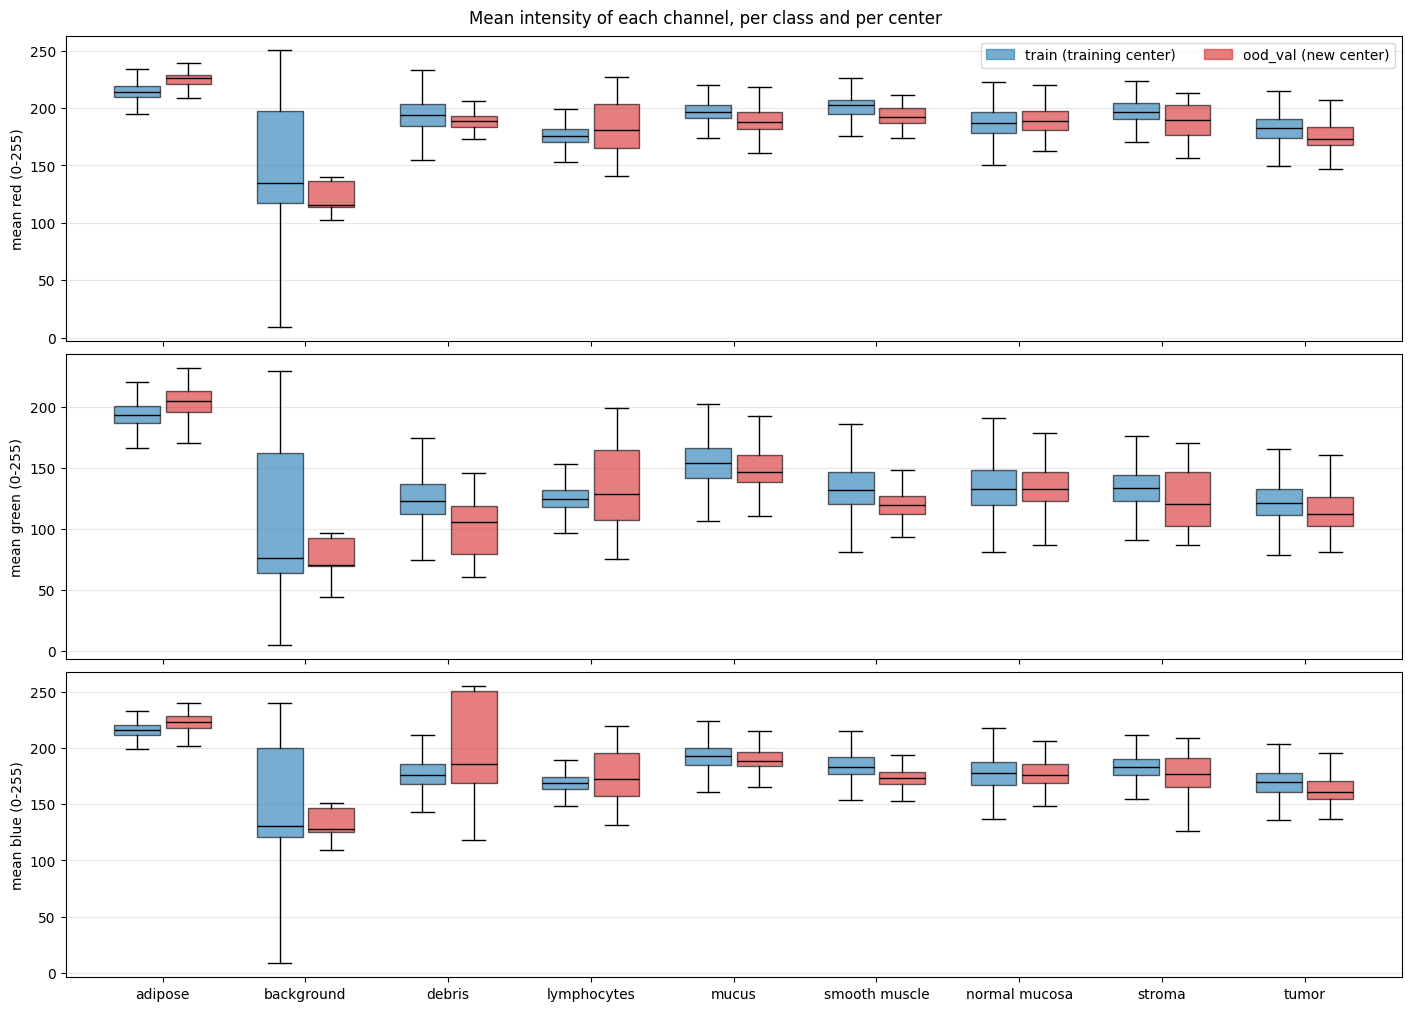

,"median RGB, train","median RGB, ood_val",color shift between centers
adipose,"(214, 194, 216)","(226, 205, 223)",17.900000
background,"(134, 76, 131)","(115, 71, 128)",20.200001
debris,"(194, 123, 176)","(189, 106, 186)",20.700001
lymphocytes,"(176, 125, 169)","(181, 128, 172)",7.100000
mucus,"(197, 154, 193)","(187, 147, 189)",12.600000
smooth muscle,"(202, 132, 183)","(192, 120, 173)",18.600000
normal colon mucosa,"(187, 133, 177)","(189, 133, 176)",1.600000
cancer-associated stroma,"(197, 134, 183)","(189, 120, 177)",16.600000
colorectal adenocarcinoma epithelium,"(182, 122, 170)","(173, 112, 161)",16.000000


Mean color shift of a class between the two centers: 14.6 (RGB units)
Mean color distance between two different classes, inside the training center: 49.9


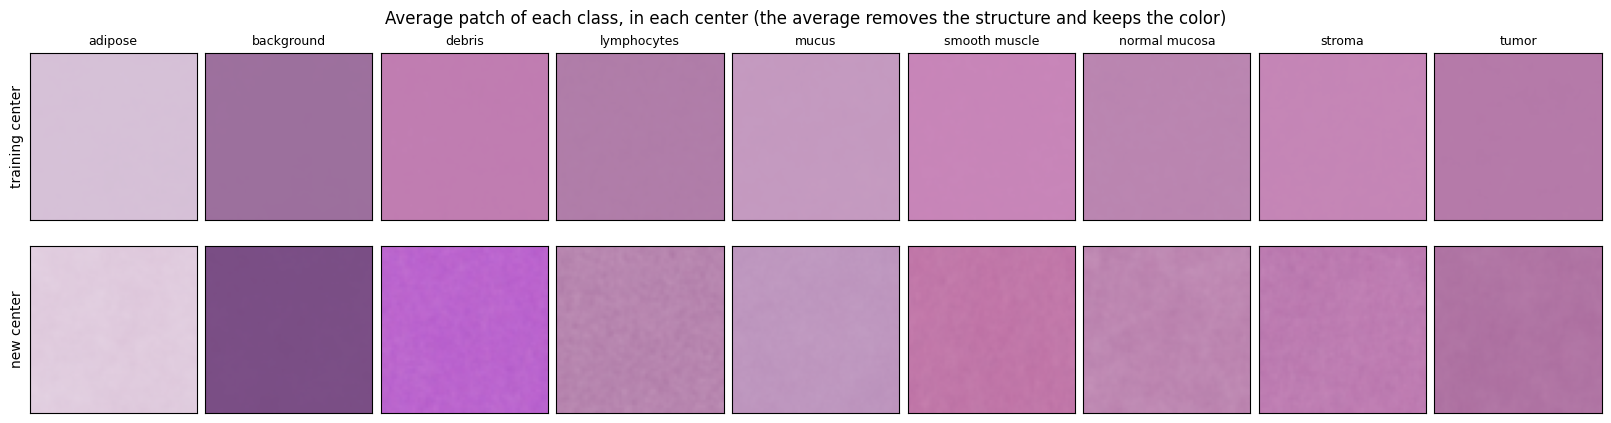

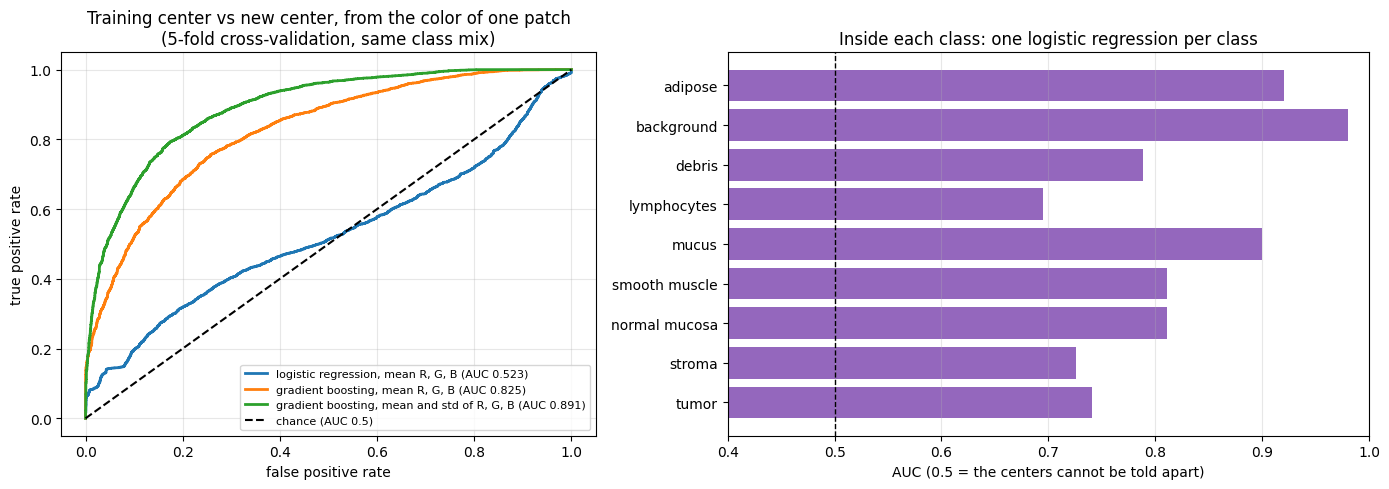

,AUC,accuracy
classifier,,
"logistic regression, mean R, G, B",0.523,0.549
"gradient boosting, mean R, G, B",0.825,0.746
"gradient boosting, mean and std of R, G, B",0.891,0.807


,AUC (one logistic regression per class)
adipose,0.920
background,0.981
debris,0.788
lymphocytes,0.695
mucus,0.900
smooth muscle,0.811
normal colon mucosa,0.811
cancer-associated stroma,0.726
colorectal adenocarcinoma epithelium,0.741


In [6]:
# Extra EDA. Only train, id_val and ood_val are used here: ood_test is never touched.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EDA_SPLITS = ["train", "id_val", "ood_val"]
SPLIT_COLORS = {"train": "tab:blue", "id_val": "tab:green", "ood_val": "tab:red"}
SHORT = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle", "normal mucosa", "stroma", "tumor"]
eda_labels = {s: SPLITS[s][1].numpy() for s in EDA_SPLITS}


def patch_color_stats(X: torch.Tensor, chunk: int = 5_000) -> np.ndarray:
    # Mean and std of each RGB channel of every patch, in 0-255. Returns (N, 6): [mean R, G, B, std R, G, B].
    out = []
    for i in range(0, len(X), chunk):
        x = X[i:i + chunk].float()
        out.append(torch.cat([x.mean(dim=(2, 3)), x.std(dim=(2, 3))], dim=1).numpy())
    return np.concatenate(out)


eda_color = {s: patch_color_stats(SPLITS[s][0]) for s in EDA_SPLITS}


# ── Figure 1: proportion of each class in each split ───────────────────────────────────────────────────────────
eda_props = pd.DataFrame({s: np.bincount(eda_labels[s], minlength=len(CLASSES)) / len(eda_labels[s])
                          for s in EDA_SPLITS}, index=CLASSES)
fig, ax = plt.subplots(figsize=(10, 5))
height = 0.27
for j, s in enumerate(EDA_SPLITS):
    ax.barh(np.arange(len(CLASSES)) + (j - 1) * height, eda_props[s] * 100, height=height, color=SPLIT_COLORS[s],
            label=f"{s} (n = {len(eda_labels[s]):,})")
ax.axvline(100 / len(CLASSES), color="black", linestyle="--", linewidth=1, label="perfectly balanced (11.1%)")
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_yticklabels(CLASSES)
ax.invert_yaxis()
ax.set_xlabel("% of the patches of the split")
ax.set_title("Class proportions: the training center and the new center have different class mixes")
ax.grid(alpha=0.3, axis="x")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)   # below the plot, hides no bar
plt.tight_layout()
plt.show()

eda_table = (eda_props * 100).round(1)
eda_table["ood_val / train"] = (eda_props["ood_val"] / eda_props["train"]).round(2)
display(eda_table)


# ── Figure 2: distribution of the mean intensity of each color channel, per split ──────────────────────────────
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ch, (ax, name) in enumerate(zip(axs, ["red", "green", "blue"])):
    for s in EDA_SPLITS:
        ax.hist(eda_color[s][:, ch], bins=60, range=(0, 255), density=True, histtype="step", linewidth=2,
                color=SPLIT_COLORS[s], label=s)
    ax.set_xlabel(f"mean {name} of the patch (0-255)")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("density")
axs[0].legend()
fig.suptitle("Mean intensity of each color channel per patch: id_val follows train, ood_val does not", fontsize=12)
plt.tight_layout()
plt.show()

display(pd.DataFrame({s: eda_color[s][:, :3].mean(axis=0) for s in EDA_SPLITS},
                     index=["mean R", "mean G", "mean B"]).T.round(1))


# ── Figure 3: the same, per class (training center vs new center) ──────────────────────────────────────────────
fig, axs = plt.subplots(3, 1, figsize=(14, 10), sharex=True, constrained_layout=True)
for ch, (ax, name) in enumerate(zip(axs, ["red", "green", "blue"])):
    for j, s in enumerate(["train", "ood_val"]):
        data = [eda_color[s][eda_labels[s] == c, ch] for c in range(len(CLASSES))]
        bp = ax.boxplot(data, positions=np.arange(len(CLASSES)) + (j - 0.5) * 0.36, widths=0.32, patch_artist=True,
                        showfliers=False)
        for box in bp["boxes"]:
            box.set_facecolor(SPLIT_COLORS[s])
            box.set_alpha(0.6)
        for med in bp["medians"]:
            med.set_color("black")
    ax.set_ylabel(f"mean {name} (0-255)")
    ax.grid(alpha=0.3, axis="y")
axs[-1].set_xticks(range(len(CLASSES)))
axs[-1].set_xticklabels(SHORT)
axs[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SPLIT_COLORS[s], alpha=0.6) for s in ["train", "ood_val"]],
              labels=["train (training center)", "ood_val (new center)"], ncol=2)
fig.suptitle("Mean intensity of each channel, per class and per center", fontsize=12)
plt.show()

eda_med = {s: np.array([np.median(eda_color[s][eda_labels[s] == c, :3], axis=0) for c in range(len(CLASSES))])
           for s in ["train", "ood_val"]}
eda_shift = np.linalg.norm(eda_med["ood_val"] - eda_med["train"], axis=1)
eda_between = [np.linalg.norm(eda_med["train"][a] - eda_med["train"][b])
               for a in range(len(CLASSES)) for b in range(a + 1, len(CLASSES))]
display(pd.DataFrame({
    "median RGB, train": [tuple(m.round().astype(int)) for m in eda_med["train"]],
    "median RGB, ood_val": [tuple(m.round().astype(int)) for m in eda_med["ood_val"]],
    "color shift between centers": eda_shift.round(1),
}, index=CLASSES))
print(f"Mean color shift of a class between the two centers: {eda_shift.mean():.1f} (RGB units)")
print(f"Mean color distance between two different classes, inside the training center: {np.mean(eda_between):.1f}")


# ── Figure 4: the average patch of each class, in each center ──────────────────────────────────────────────────
def class_mean_patch(X: torch.Tensor, y: torch.Tensor, c: int, chunk: int = 2_000) -> np.ndarray:
    idx = torch.from_numpy(np.flatnonzero(y.numpy() == c))
    total = torch.zeros(3, 64, 64, dtype=torch.float64)
    for i in range(0, len(idx), chunk):
        total += X[idx[i:i + chunk]].double().sum(dim=0)
    return (total / len(idx)).permute(1, 2, 0).numpy() / 255


fig, axs = plt.subplots(2, len(CLASSES), figsize=(16, 4.2), constrained_layout=True)
for row, (s, title) in enumerate([("train", "training center"), ("ood_val", "new center")]):
    X, y = SPLITS[s]
    for c in range(len(CLASSES)):
        axs[row, c].imshow(class_mean_patch(X, y, c))
        axs[row, c].set_xticks([])
        axs[row, c].set_yticks([])
        if row == 0:
            axs[row, c].set_title(SHORT[c], fontsize=9)
    axs[row, 0].set_ylabel(title, fontsize=10)
fig.suptitle("Average patch of each class, in each center (the average removes the structure and keeps the color)",
             fontsize=12)
plt.show()


# ── Figure 5: can a simple classifier tell the two centers apart from the color of a patch? ────────────────────
# The new center has a different class mix, so a classifier could cheat with the class proportions. To avoid
# that, we draw training patches with exactly the same class mix as ood_val.
eda_rng = np.random.default_rng(seed)
train_idx = np.concatenate([
    eda_rng.choice(np.flatnonzero(eda_labels["train"] == c), size=int((eda_labels["ood_val"] == c).sum()), replace=False)
    for c in range(len(CLASSES))
])
y_center = np.r_[np.zeros(len(train_idx)), np.ones(len(eda_labels["ood_val"]))]      # 0 = training center, 1 = new
y_class = np.r_[eda_labels["train"][train_idx], eda_labels["ood_val"]]
feats = np.vstack([eda_color["train"][train_idx], eda_color["ood_val"]])             # mean and std of R, G, B

# A linear model on the color of the whole patch, and a non-linear one on the same features.
eda_models = {
    "logistic regression, mean R, G, B": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1_000)), feats[:, :3]),
    "gradient boosting, mean R, G, B": (HistGradientBoostingClassifier(max_iter=200, random_state=seed), feats[:, :3]),
    "gradient boosting, mean and std of R, G, B": (HistGradientBoostingClassifier(max_iter=200, random_state=seed), feats),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

fig, axs = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.2]})
rows = []
for name, (clf, F) in eda_models.items():
    p = cross_val_predict(clf, F, y_center, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_center, p)
    auc = roc_auc_score(y_center, p)
    axs[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC {auc:.3f})")
    rows.append({"classifier": name, "AUC": round(auc, 3), "accuracy": round(((p > 0.5) == y_center).mean(), 3)})
axs[0].plot([0, 1], [0, 1], "k--", label="chance (AUC 0.5)")
axs[0].set_xlabel("false positive rate")
axs[0].set_ylabel("true positive rate")
axs[0].set_title("Training center vs new center, from the color of one patch\n(5-fold cross-validation, same class mix)")
axs[0].grid(alpha=0.3)
axs[0].legend(loc="lower right", fontsize=8)

# Same question inside each class: one logistic regression per class, on the mean and std of R, G, B.
per_class_auc = []
for c in range(len(CLASSES)):
    m = y_class == c
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1_000))
    p = cross_val_predict(clf, feats[m], y_center[m], cv=StratifiedKFold(5, shuffle=True, random_state=seed),
                          method="predict_proba")[:, 1]
    per_class_auc.append(roc_auc_score(y_center[m], p))
axs[1].barh(np.arange(len(CLASSES)), per_class_auc, color="tab:purple")
axs[1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axs[1].set_yticks(np.arange(len(CLASSES)))
axs[1].set_yticklabels(SHORT)
axs[1].invert_yaxis()
axs[1].set_xlim(0.4, 1.0)
axs[1].set_xlabel("AUC (0.5 = the centers cannot be told apart)")
axs[1].set_title("Inside each class: one logistic regression per class")
axs[1].grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).set_index("classifier"))
display(pd.DataFrame({"AUC (one logistic regression per class)": np.round(per_class_auc, 3)}, index=CLASSES))

> **Question.** (1.0 pt)
>
> What are your findings? Describe the task, the balance of the classes, and how the two centers differ. Which
> properties of the patches seem to be stable across centers, and which change from one center to the other?
>
> Based only on this exploration, predict which architecture, MLP or CNN, is more likely to rely on properties that
> change between centers, and why.

**A tarefa.** É uma classificação de tecido em 9 classes: o modelo recebe um patch de 64x64 pixels RGB de uma lâmina corada com H&E e precisa dizer se é gordura, fundo, debris, linfócitos, muco, músculo liso, mucosa normal, estroma ou tumor. Pelos exemplos, algumas classes dá pra reconhecer quase só pela cor (o adipose é claro e quase branco, o background é um roxo escuro e liso). Já debris, músculo liso, estroma, mucosa normal e tumor têm um rosa-roxo parecido nas imagens médias (figura 4), então a separação delas depende mais da forma e do arranjo das células: fibras alongadas no músculo, glândulas em anel na mucosa normal, núcleos aglomerados no tumor e nos linfócitos.

**Balanço das classes.** No treino as classes são razoavelmente balanceadas, indo de 8,8% (mucosa normal) a 14,3% (tumor), e o `id_val` tem as mesmas proporções do treino até a primeira casa decimal. No novo centro (`ood_val`) a mistura muda bastante: o adipose sobe de 10,4% para 18,6% (1,79 vez mais) e o muco de 8,9% para 14,4% (1,62 vez), enquanto o debris cai de 11,5% para 4,7% (0,41 vez), o estroma de 10,4% para 5,8% e o músculo liso de 13,5% para 8,2%. Ou seja, a acurácia comum pode mudar só porque a mistura de classes é outra, e é por isso que o notebook usa a acurácia balanceada.

**Como os centros diferem.** A cor média geral quase não muda (o vermelho médio é 188,8 no treino e 185,3 no `ood_val`), mas isso engana, porque o deslocamento depende da classe. O adipose do novo centro fica mais claro (mediana RGB de (214, 194, 216) para (226, 205, 223)), enquanto o background escurece (de (134, 76, 131) para (115, 71, 128)) e debris, músculo liso, estroma e tumor também mudam de tom. Em média, uma classe se desloca 14,6 unidades de RGB entre os centros, contra 49,9 de distância média entre duas classes diferentes dentro do treino. Os maiores deslocamentos são do debris (20,7), do background (20,2) e do músculo liso (18,6). Dois dos quatro patches de debris do novo centro que aparecem nos exemplos são de um violeta bem saturado, e isso aparece na imagem média e na caixa do canal azul.

Pra medir esse deslocamento, tentamos adivinhar o centro de um patch só pela cor, com a mesma mistura de classes dos dois lados para o classificador não usar as proporções de classe. Uma regressão logística sobre a cor média RGB ficou quase no acaso (AUC 0,523), mas isso acontece porque o deslocamento tem sentido diferente em cada classe (o adipose clareia, enquanto a maioria das outras escurece ou muda de tom, e linfócitos e mucosa normal quase não mexem) e um modelo linear sobre o patch inteiro não consegue representar isso. Com um modelo não linear (gradient boosting) sobre as mesmas três médias a AUC sobe para 0,826 (acurácia 0,747), e com média e desvio dos canais vai para 0,890 (acurácia 0,808). Dentro de cada classe, uma regressão logística por classe também separa os centros, com AUC de 0,695 (linfócitos) a 0,981 (background). Então a cor sozinha já entrega de qual centro veio o patch, e dizer que a cor quase não muda seria errado. Uma ressalva é que a validação cruzada foi por patch, e patches da mesma lâmina podem cair em dobras diferentes, então esses números podem estar um pouco otimistas, principalmente os do modelo não linear.

**O que parece estável.** A forma e o arranjo das estruturas aparecem iguais nos dois centros nos exemplos: células de gordura grandes e claras com paredes finas no adipose, núcleos pequenos e densos nos linfócitos, glândulas em anel na mucosa normal, fibras alongadas no músculo liso. Também se mantêm o conjunto de classes, a paleta rosa-roxa do H&E e a ordem aproximada de claridade das classes (o adipose é o mais claro e o background o mais escuro nos dois centros).

**O que muda.** A cor de cada classe (deslocamento médio de 14,6 unidades RGB), a mistura de classes e a distribuição das cores: o histograma do `id_val` cai em cima do `train`, mas o do `ood_val` tem picos estreitos e deslocados, o que nosso palpite diz que vem de poucas lâminas com tons bem definidos. Nos exemplos também notamos que dois dos quatro patches de background do treino têm uma textura quadriculada que não aparece nos do novo centro, mas são só quatro exemplos, então é só um indício.

**Previsão: MLP ou CNN?** Nosso palpite é que o MLP é o que mais tende a se apoiar em propriedades que mudam de centro. Primeiro, porque existe um atalho de cor disponível: a cor distingue as classes bem mais do que distingue os centros (49,9 contra 14,6), mas varia de um centro pro outro. Segundo, porque as imagens médias de cada classe são quase uma cor uniforme, então a forma mais simples de um MLP, que tem um peso para cada pixel e canal, usar essas entradas parece ser somando a cor e o brilho do patch inteiro, que é justamente o que muda. Terceiro, o que é estável é a forma local das células, e é esse tipo de padrão que filtros pequenos e compartilhados da CNN detectam em qualquer posição, enquanto o MLP teria que aprender isso pixel a pixel. Uma ressalva é que a CNN também recebe as cores (os filtros da primeira camada veem o RGB), então ela também pode pegar o atalho da cor. Nossa previsão é só que ela tem mais facilidade de usar a morfologia, não que ela ignore a cor, e isso a gente testa nos Experimentos 1 e 3.

---

## Training utilities

All the experiments train and evaluate models with the same four functions, which you will implement in the next
cell. The hands-on of Lecture 18 contains a training loop that you can start from.

> **Implementation.** (1.0 pt)
>
> Implement the four functions below, keeping their names, arguments and return values, since the rest of the notebook
> uses them:
>
> - `make_loader(split, batch_size, shuffle, shuffle_seed)` returns a `DataLoader` over the patches and labels of
>   `SPLITS[split]`. When `shuffle=True`, the order must be **reproducible**: shuffle with a `torch.Generator` seeded
>   with `shuffle_seed`.
> - `predict(model, loader, preprocess, input_fn=None)` returns the predicted classes and the true labels of a whole
>   loader, as two NumPy arrays. Each batch goes through `preprocess` and then, if it is given, through `input_fn`
>   (used in Experiment 2). The model must be in evaluation mode, and no gradients are needed.
> - `evaluate(model, loader, preprocess, input_fn=None)` returns `{"acc": ..., "bal_acc": ...}`, the accuracy and the
>   balanced accuracy of the predictions of `predict`.
> - `fit(model, train_loader, val_loader, optimizer, n_epochs, preprocess, augment=None, verbose=True)` trains the
>   model with `nn.CrossEntropyLoss` (all models output **9 logits** per patch, and the loss applies the softmax).
>   Each training batch goes through `preprocess(x, augment)`. After every epoch, `fit` evaluates the model on
>   `val_loader` and keeps a copy of the weights of the epoch with the best **ID validation balanced accuracy** (early
>   stopping). At the end it restores those weights, so the model used afterwards is the one of the best epoch. It
>   returns a dictionary `history` with:
>   - `"train_loss"`, `"train_acc"`, `"val_acc"`, `"val_bal_acc"`: lists with one value per epoch;
>   - `"best_epoch"`: the epoch whose weights were kept, counting from 1;
>   - `"train_time"`: the total training time, in seconds.
>
>   With `verbose=True`, it prints the metrics of each epoch.
>
> Model selection inside `fit` must use only the ID validation split. Run the sanity check below before starting the
> experiments.

The cell after your implementation is already complete:
- `report` evaluates a trained model on the ID and the OOD validation splits and stores the results in `RESULTS`,
  which you will use in the Summary table;
- `plot_histories` plots the histories returned by `fit`.

In [7]:
def make_loader(split: str, batch_size: int = 512, shuffle: bool = False, shuffle_seed: int = seed) -> DataLoader:
    # The patches stay as uint8 on the CPU: Preprocess moves each batch to the device and converts it to float.
    X, y = SPLITS[split]
    # A generator seeded with shuffle_seed makes the order of the batches reproducible (None keeps the original order).
    generator = torch.Generator().manual_seed(shuffle_seed) if shuffle else None
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle, generator=generator,
                      pin_memory=(DEVICE == "cuda"))


def predict(model: nn.Module, loader: DataLoader, preprocess: Preprocess, input_fn=None) -> tuple[np.ndarray, np.ndarray]:
    # Predicted classes (argmax of the logits) and true labels of the whole loader, as NumPy arrays.
    model.eval()                                  # dropout off and batch norm with its running statistics
    preds, labels = [], []
    with torch.no_grad():                         # no gradients are needed to predict
        for x, y in loader:
            x = preprocess(x)
            if input_fn is not None:              # e.g. a rotation of the already standardized patches (Experiment 2)
                x = input_fn(x)
            preds.append(model(x).argmax(dim=1).cpu())
            labels.append(y)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()


def evaluate(model: nn.Module, loader: DataLoader, preprocess: Preprocess, input_fn=None) -> dict[str, float]:
    # Accuracy and balanced accuracy (mean of the recalls of the classes) of the predictions of predict().
    preds, labels = predict(model, loader, preprocess, input_fn)
    return {"acc": float((preds == labels).mean()), "bal_acc": float(balanced_accuracy_score(labels, preds))}


def fit(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, optimizer: optim.Optimizer,
        n_epochs: int, preprocess: Preprocess, augment=None, verbose: bool = True) -> dict:
    # Training loop with early stopping on the ID validation balanced accuracy: the weights of the best epoch are
    # kept and restored at the end. The ID validation split is the only one used to choose the epoch.
    criterion = nn.CrossEntropyLoss()              # the model outputs logits, the loss applies the softmax
    history = {"train_loss": [], "train_acc": [], "val_acc": [], "val_bal_acc": [], "best_epoch": None,
               "train_time": None}
    best_bal_acc, best_state = -1.0, None
    start = time.perf_counter()

    for epoch in range(1, n_epochs + 1):
        model.train()
        loss_sum, n_correct, n_seen = 0.0, 0, 0
        for x, y in train_loader:
            x = preprocess(x, augment)             # augmentation (if any) only on training batches
            y = y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)       # the loss is a mean over the batch: weight it by the batch size
            n_correct += (logits.argmax(dim=1) == y).sum().item()
            n_seen += len(y)

        val = evaluate(model, val_loader, preprocess)
        history["train_loss"].append(loss_sum / n_seen)    # measured while training (with dropout/augmentation on)
        history["train_acc"].append(n_correct / n_seen)
        history["val_acc"].append(val["acc"])
        history["val_bal_acc"].append(val["bal_acc"])

        is_best = val["bal_acc"] > best_bal_acc            # strict ">": on a tie the earliest epoch is kept
        if is_best:
            best_bal_acc, history["best_epoch"] = val["bal_acc"], epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"epoch {epoch:>2}/{n_epochs} | train loss {history['train_loss'][-1]:.4f} | "
                  f"train acc {history['train_acc'][-1]:.3f} | val acc {val['acc']:.3f} | "
                  f"val bal. acc {val['bal_acc']:.3f}" + (" *" if is_best else ""))

    model.load_state_dict(best_state)              # back to the weights of the best epoch
    history["train_time"] = time.perf_counter() - start   # whole call, including the validation after each epoch
    return history

In [9]:
RESULTS: dict[str, dict] = {}   # one row per trained model, filled by report()
MODELS: dict[str, tuple] = {}   # name -> (model, Preprocess used to evaluate it)


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def report(name: str, model: nn.Module, preprocess: Preprocess, history: dict | None = None) -> dict:
    # ID and OOD validation metrics of a trained model, stored in RESULTS.
    id_m = evaluate(model, make_loader("id_val"), preprocess)
    ood_m = evaluate(model, make_loader("ood_val"), preprocess)
    RESULTS[name] = {
        "params": count_params(model),
        "train_time_s": round(history["train_time"]) if history else None,
        "id_acc": id_m["acc"], "id_bal_acc": id_m["bal_acc"],
        "ood_acc": ood_m["acc"], "ood_bal_acc": ood_m["bal_acc"],
        "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"],
    }
    MODELS[name] = (model, preprocess)
    r = RESULTS[name]
    print(f"{name}: ID bal. acc {r['id_bal_acc']:.3f} | OOD bal. acc {r['ood_bal_acc']:.3f} | gap {r['gap_bal_acc']:+.3f} "
          f"| ID acc {r['id_acc']:.3f} | OOD acc {r['ood_acc']:.3f}")
    return r


def plot_histories(histories: dict[str, dict], title: str = "") -> None:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    for (name, h), color in zip(histories.items(), plt.cm.tab10.colors):
        epochs = range(1, len(h["train_loss"]) + 1)
        axs[0].plot(epochs, h["train_loss"], color=color, label=name)
        axs[1].plot(epochs, h["train_acc"], "--", color=color, alpha=0.7)
        axs[1].plot(epochs, h["val_acc"], color=color, label=name)
        axs[2].plot(epochs, h["val_bal_acc"], color=color, label=name)
        best = h["best_epoch"]
        axs[2].scatter(best, h["val_bal_acc"][best - 1], marker="*", s=150, color=color, edgecolor="black", zorder=5)
    titles = ["training loss", "accuracy (dashed = train, solid = ID val)", "ID val balanced accuracy (star = kept epoch)"]
    for ax, t in zip(axs, titles):
        ax.set_title(t)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

In [10]:
# Sanity check of your implementation, with a tiny model and 2,000 training patches (a few seconds).
torch.manual_seed(seed)
check_model = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(3 * 64 * 64, len(CLASSES))).to(DEVICE)
check_train = DataLoader(TensorDataset(X_train[:2_000], y_train[:2_000]), batch_size=128, shuffle=True)
check_val = DataLoader(TensorDataset(X_id_val[:1_000], y_id_val[:1_000]), batch_size=512)
check_history = fit(check_model, check_train, check_val, optim.Adam(check_model.parameters(), lr=1e-3), 3, rgb,
                    verbose=False)

preds, labels = predict(check_model, check_val, rgb)
assert preds.shape == labels.shape == (1_000,), "predict must return one prediction and one label per patch"
assert np.array_equal(preds, predict(check_model, check_val, rgb)[0]), "predict must put the model in evaluation mode"
for key in ["train_loss", "train_acc", "val_acc", "val_bal_acc"]:
    assert len(check_history[key]) == 3, f'history["{key}"] must have one value per epoch'
assert check_history["train_time"] is not None, 'history["train_time"] is missing'
best = check_history["best_epoch"]
assert best in (1, 2, 3) and check_history["val_bal_acc"][best - 1] == max(check_history["val_bal_acc"]), \
    "best_epoch must be the epoch with the best ID validation balanced accuracy, counting from 1"
assert abs(evaluate(check_model, check_val, rgb)["bal_acc"] - check_history["val_bal_acc"][best - 1]) < 1e-6, \
    "fit must restore the weights of the best epoch"
first_batch = lambda: next(iter(make_loader("train", batch_size=8, shuffle=True)))[1]
assert torch.equal(first_batch(), first_batch()), "the shuffled order must be reproducible (use shuffle_seed)"
print("All checks passed.")

All checks passed.


---

## Experiment 1: Is the Convolutional Structure Necessary?

A CNN builds three assumptions into the network:
- **locality**: each unit of a convolutional layer looks only at a small neighborhood of the previous layer;
- **weight sharing**: the same filter is applied at every position, so a pattern is detected wherever it appears;
- **hierarchy**: deeper layers combine the patterns of earlier ones, over larger and larger regions.

An MLP applied to the flattened pixels has none of them: each of the 64×64×3 = 12,288 inputs has its own weight in
every unit of the first layer, and any spatial relationship must be learned from the data. In Lecture 18, the same
MLP that worked on Fashion-MNIST (centered, aligned objects) failed on CIFAR-10 (objects anywhere in the image),
while a CNN with 5 times fewer parameters did much better. Are tissue patches closer to the first case or to the
second?

This comparison also illustrates that **the number of parameters does not determine generalization**: the first
layer of the MLP alone has about 65 times more parameters than the whole SmallCNN.

> **Question:**
>
> Does the spatial inductive bias of a CNN improve in-distribution performance *and* generalization to a new
> clinical center, compared with an MLP with many more parameters trained under the same conditions?

> **Hypothesis:**
>
> A tissue class is defined by local patterns (the shape, size and density of nuclei and fibers, the arrangement of
> glands and cells), which can appear at any position of the patch and are the same in every center. A SmallCNN, which
> detects local patterns anywhere with shared filters, will therefore reach a **higher balanced accuracy than the MLP
> on both the ID and the OOD validation splits**, and a **smaller ID–OOD gap**, despite having more than 60 times fewer
> parameters.
> The hypothesis is contradicted if the MLP matches or beats the CNN on the OOD validation balanced accuracy, or if the
> gap of the CNN is not smaller than the gap of the MLP.

> **Baseline:**
>
> A classifier that always predicts the same class has balanced accuracy 1/9 ≈ 0.11.

In [11]:
class MLP(nn.Module):
    # Fully connected network on the flattened patch: no spatial inductive bias.

    def __init__(self, input_size: int, hidden_sizes: list[int], n_classes: int = 9, dropout: float = 0.0) -> None:
        super().__init__()
        # Flatten -> [Linear -> ReLU -> Dropout] for each hidden size -> Linear(last hidden size, n_classes).
        # The layers live in `self.net` so that `net[:-1]` is the part that gives the last hidden representation.
        layers: list[nn.Module] = [nn.Flatten()]
        in_features = input_size
        for hidden in hidden_sizes:
            layers += [nn.Linear(in_features, hidden), nn.ReLU(), nn.Dropout(dropout)]
            in_features = hidden
        layers.append(nn.Linear(in_features, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x has shape (batch, 3, 64, 64); the logits have shape (batch, n_classes).
        return self.net(x)


class SmallCNN(nn.Module):
    # Small convolutional network: locality, weight sharing and hierarchy.

    def __init__(self, channels: tuple[int, ...] = (32, 64, 128), n_classes: int = 9) -> None:
        super().__init__()
        # One block per entry of `channels`: Conv2d(3x3, padding=1) -> BatchNorm2d -> ReLU -> MaxPool2d(2).
        # Then AdaptiveAvgPool2d(1) -> Flatten -> Linear(channels[-1], n_classes). As in the MLP, `net[:-1]` is the part
        # that gives the last hidden representation (here, the 128 pooled features).
        blocks: list[nn.Module] = []
        in_channels = 3
        for out_channels in channels:
            blocks += [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1), nn.BatchNorm2d(out_channels),
                       nn.ReLU(), nn.MaxPool2d(2)]
            in_channels = out_channels
        self.net = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(channels[-1], n_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x has shape (batch, 3, 64, 64); the logits have shape (batch, n_classes).
        return self.net(x)

In [12]:
mlp = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256])
cnn = SmallCNN()

print(f"MLP parameters      : {count_params(mlp):>12,}")
print(f"SmallCNN parameters : {count_params(cnn):>12,}")
print()
print("Both models receive the same standardized 64x64x3 patches and are trained with the same loop.")

MLP parameters      :    6,425,609
SmallCNN parameters :       94,857

Both models receive the same standardized 64x64x3 patches and are trained with the same loop.


In [13]:
train_loader = make_loader("train", batch_size=128, shuffle=True)
id_val_loader = make_loader("id_val")

# Both models are trained under the same conditions: Adam with the same learning rate, the same number of epochs, the
# same batch size and the same order of batches. The weights of the best epoch on the ID validation split are the ones
# kept by fit(), so the number of epochs only has to be large enough. The only regularization in the main comparison is
# that early stopping: the CNN has no dropout, so the MLP does not have it either (dropout = 0). A control with dropout
# for the MLP is trained in the analysis cell.
learning_rate = 1e-3     # the same value used with Adam in the sanity check of the notebook
n_epochs = 10
dropout = 0.0

In [14]:
torch.manual_seed(seed)
mlp = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=dropout).to(DEVICE)
mlp_optimizer = optim.Adam(mlp.parameters(), lr=learning_rate)

mlp_history = fit(mlp, train_loader, id_val_loader, mlp_optimizer, n_epochs, rgb)
report("MLP (Exp. 1)", mlp, rgb, mlp_history);

epoch  1/10 | train loss 1.1794 | train acc 0.555 | val acc 0.522 | val bal. acc 0.510 *
epoch  2/10 | train loss 0.9103 | train acc 0.654 | val acc 0.635 | val bal. acc 0.626 *
epoch  3/10 | train loss 0.7961 | train acc 0.698 | val acc 0.575 | val bal. acc 0.564
epoch  4/10 | train loss 0.7148 | train acc 0.735 | val acc 0.638 | val bal. acc 0.638 *
epoch  5/10 | train loss 0.6179 | train acc 0.773 | val acc 0.655 | val bal. acc 0.648 *
epoch  6/10 | train loss 0.5375 | train acc 0.807 | val acc 0.660 | val bal. acc 0.657 *
epoch  7/10 | train loss 0.4445 | train acc 0.841 | val acc 0.654 | val bal. acc 0.652
epoch  8/10 | train loss 0.3764 | train acc 0.868 | val acc 0.664 | val bal. acc 0.661 *
epoch  9/10 | train loss 0.3391 | train acc 0.882 | val acc 0.657 | val bal. acc 0.657
epoch 10/10 | train loss 0.3052 | train acc 0.895 | val acc 0.653 | val bal. acc 0.651
MLP (Exp. 1): ID bal. acc 0.661 | OOD bal. acc 0.574 | gap +0.087 | ID acc 0.664 | OOD acc 0.628


In [15]:
torch.manual_seed(seed)
cnn = SmallCNN().to(DEVICE)
cnn_optimizer = optim.Adam(cnn.parameters(), lr=learning_rate)

# New loader with the same seed: the CNN sees exactly the same sequence of batches that the MLP saw.
train_loader = make_loader("train", batch_size=128, shuffle=True)
cnn_history = fit(cnn, train_loader, id_val_loader, cnn_optimizer, n_epochs, rgb)
report("SmallCNN (Exp. 1)", cnn, rgb, cnn_history);

epoch  1/10 | train loss 0.4359 | train acc 0.861 | val acc 0.781 | val bal. acc 0.779 *
epoch  2/10 | train loss 0.1882 | train acc 0.939 | val acc 0.843 | val bal. acc 0.844 *
epoch  3/10 | train loss 0.1432 | train acc 0.954 | val acc 0.919 | val bal. acc 0.912 *
epoch  4/10 | train loss 0.1191 | train acc 0.962 | val acc 0.943 | val bal. acc 0.940 *
epoch  5/10 | train loss 0.1054 | train acc 0.966 | val acc 0.959 | val bal. acc 0.960 *
epoch  6/10 | train loss 0.0918 | train acc 0.970 | val acc 0.955 | val bal. acc 0.953
epoch  7/10 | train loss 0.0841 | train acc 0.973 | val acc 0.965 | val bal. acc 0.964 *
epoch  8/10 | train loss 0.0766 | train acc 0.975 | val acc 0.936 | val bal. acc 0.934
epoch  9/10 | train loss 0.0695 | train acc 0.977 | val acc 0.982 | val bal. acc 0.981 *
epoch 10/10 | train loss 0.0665 | train acc 0.978 | val acc 0.971 | val bal. acc 0.971
SmallCNN (Exp. 1): ID bal. acc 0.981 | OOD bal. acc 0.834 | gap +0.147 | ID acc 0.982 | OOD acc 0.858


MLP + dropout 0.3 (Exp. 1 control): ID bal. acc 0.650 | OOD bal. acc 0.578 | gap +0.072 | ID acc 0.650 | OOD acc 0.621


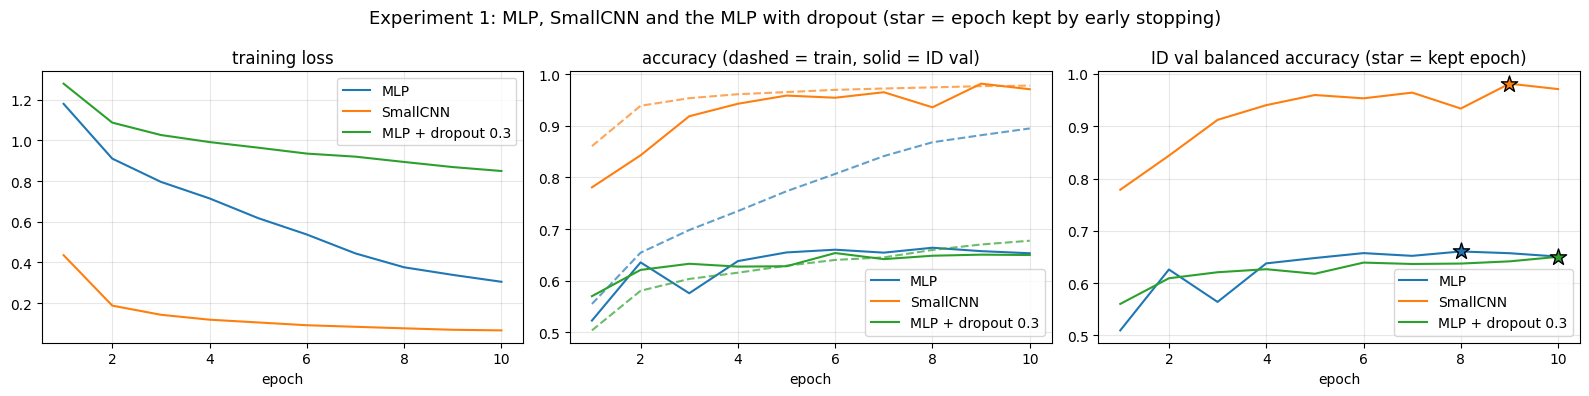

,params,train time (s),best epoch,train bal. acc,ID bal. acc,OOD bal. acc,gap,ID acc,OOD acc
MLP,6425609.0,38.0,8.0,0.890,0.661,0.574,0.087,0.664,0.628
SmallCNN,94857.0,232.0,9.0,0.982,0.981,0.834,0.147,0.982,0.858
MLP + dropout 0.3,6425609.0,39.0,10.0,0.747,0.650,0.578,0.072,0.650,0.621


train bal. acc: balanced accuracy in evaluation mode on 10,000 random training patches.


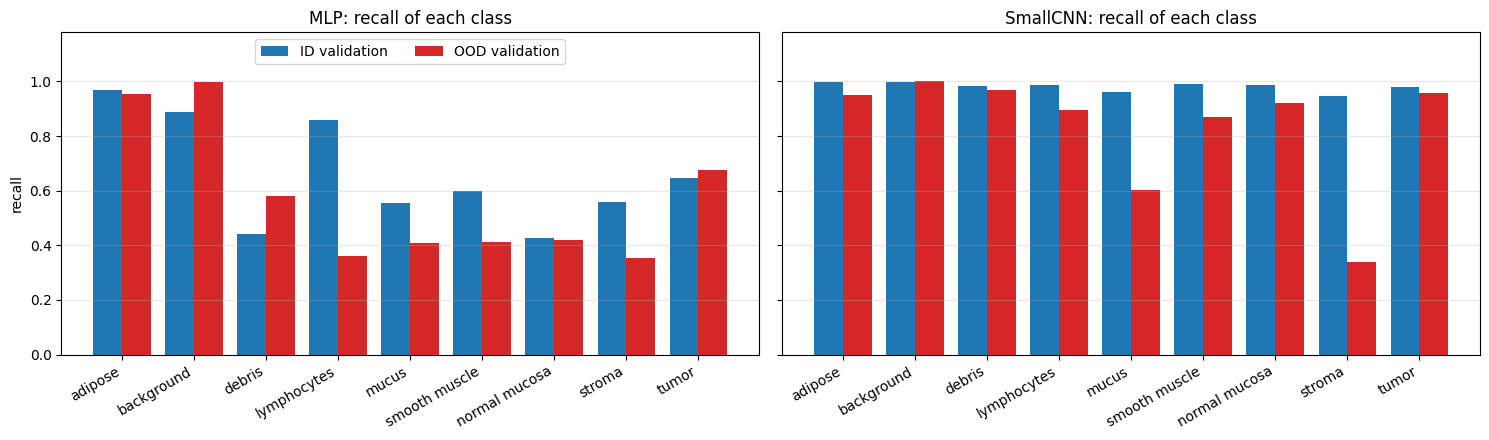

,MLP ID,MLP OOD,MLP drop,SmallCNN ID,SmallCNN OOD,SmallCNN drop
adipose,0.967,0.954,0.014,0.998,0.949,0.049
background,0.886,0.998,-0.111,0.999,1.000,-0.001
debris,0.443,0.582,-0.140,0.982,0.971,0.011
lymphocytes,0.861,0.360,0.501,0.987,0.896,0.091
mucus,0.556,0.409,0.147,0.962,0.604,0.358
smooth muscle,0.600,0.412,0.188,0.991,0.868,0.123
normal mucosa,0.425,0.419,0.006,0.986,0.922,0.065
stroma,0.560,0.352,0.207,0.946,0.338,0.608
tumor,0.647,0.677,-0.030,0.981,0.959,0.022


MLP: classes that lose the most recall on the new center: lymphocytes (0.50), stroma (0.21), smooth muscle (0.19)
SmallCNN: classes that lose the most recall on the new center: stroma (0.61), mucus (0.36), smooth muscle (0.12)


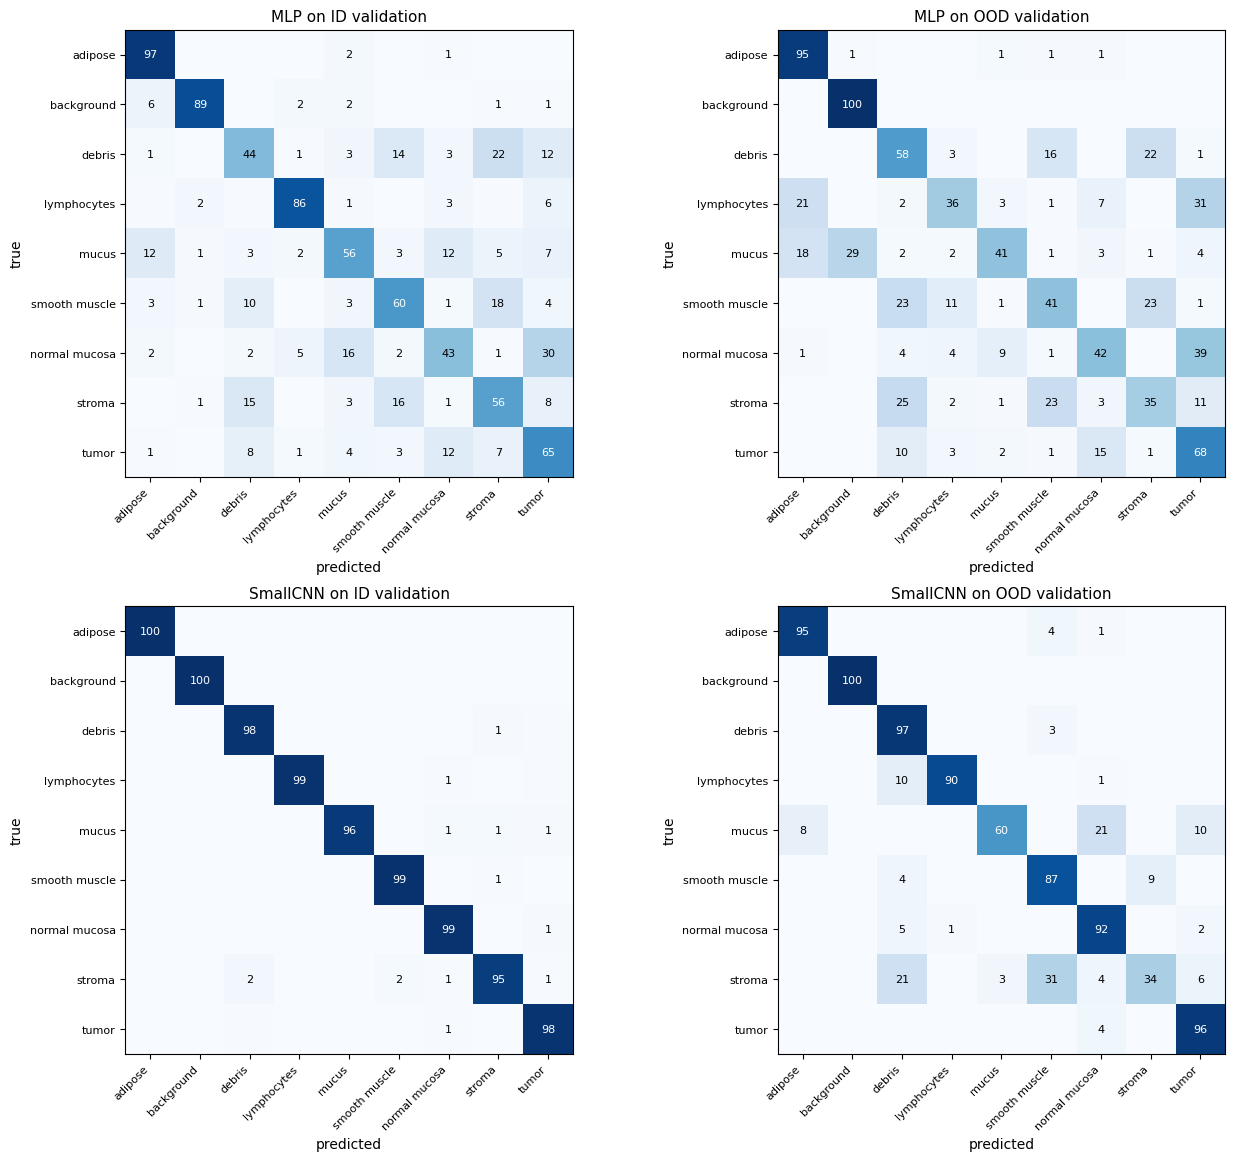

MLP, largest confusions on the new center: normal mucosa -> tumor (39% of the normal mucosa patches); lymphocytes -> tumor (31% of the lymphocytes patches); mucus -> background (29% of the mucus patches)
SmallCNN, largest confusions on the new center: stroma -> smooth muscle (31% of the stroma patches); stroma -> debris (21% of the stroma patches); mucus -> normal mucosa (21% of the mucus patches)


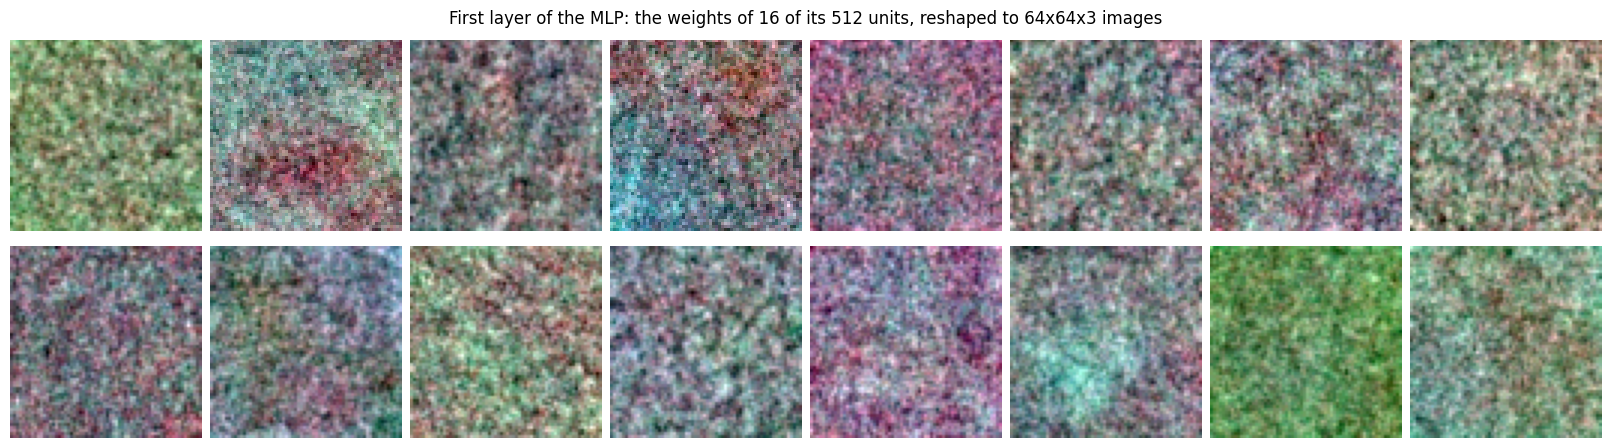

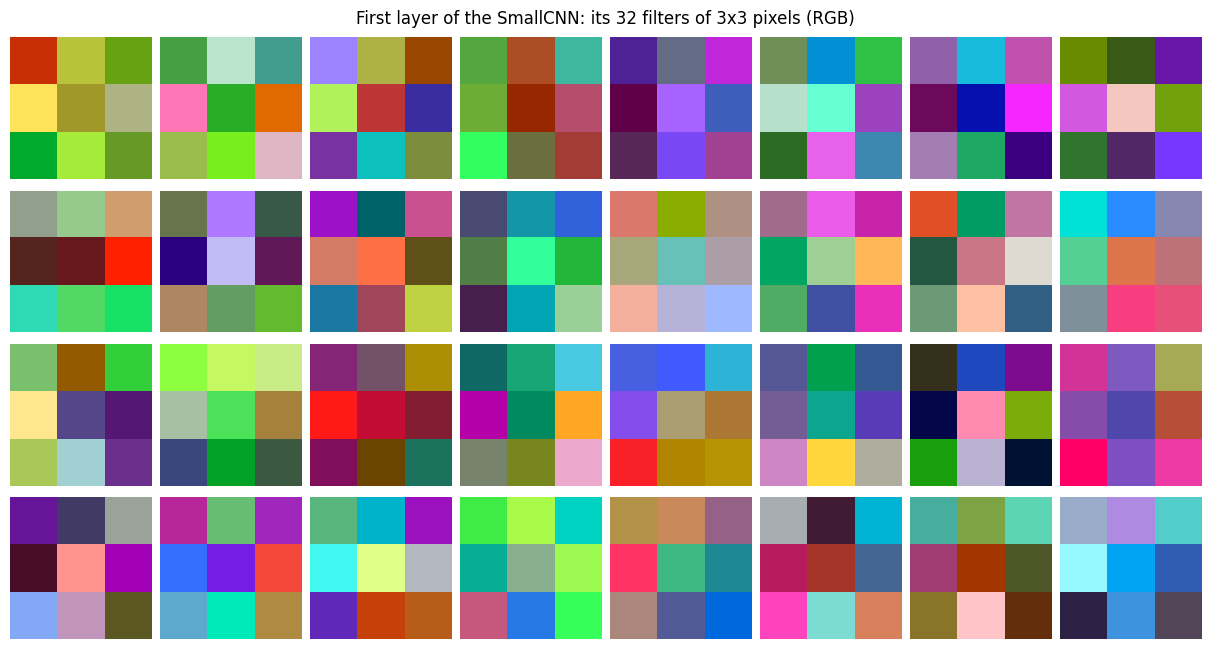

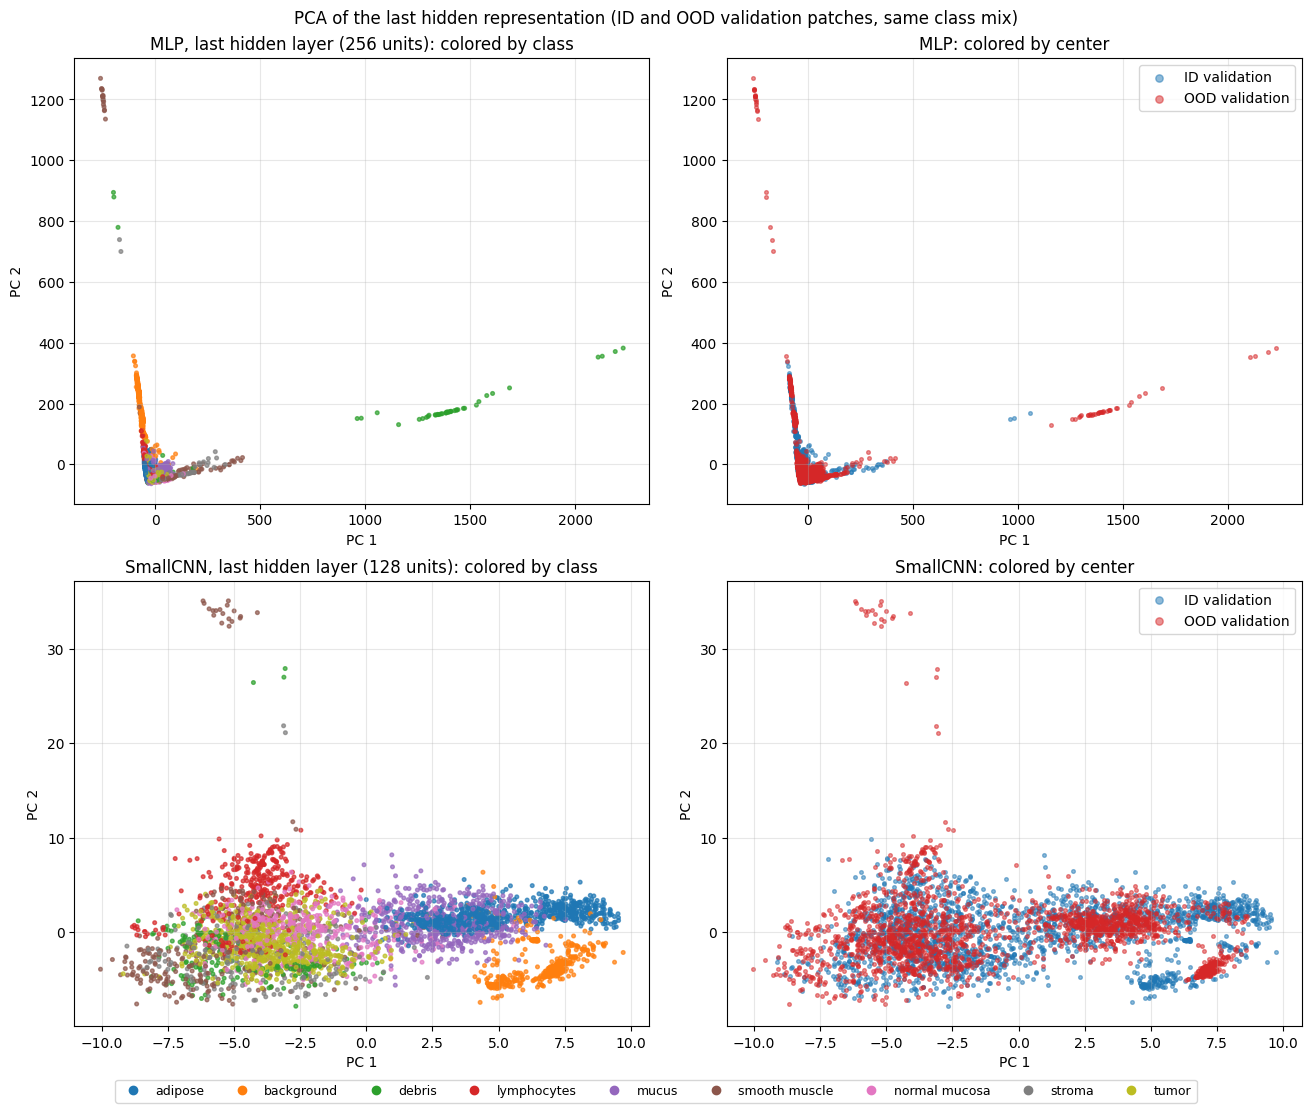

AUC of a logistic regression that tells ID from OOD patches using the last hidden representation (0.5 = the center is invisible): {'MLP': np.float64(0.745), 'SmallCNN': np.float64(0.939)}


In [16]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ── Control: the same MLP, trained in the same conditions, but with dropout 0.3 ────────────────────────────────────
# The main MLP has no regularization except early stopping. This control checks that the comparison with the CNN does
# not depend on that choice. It is not used as "the MLP" of the experiment.
torch.manual_seed(seed)
mlp_drop = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=0.3).to(DEVICE)
mlp_drop_history = fit(mlp_drop, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                       optim.Adam(mlp_drop.parameters(), lr=learning_rate), n_epochs, rgb, verbose=False)
report("MLP + dropout 0.3 (Exp. 1 control)", mlp_drop, rgb, mlp_drop_history);

NAMES = {"MLP": "MLP (Exp. 1)", "SmallCNN": "SmallCNN (Exp. 1)", "MLP + dropout 0.3": "MLP + dropout 0.3 (Exp. 1 control)"}
HISTORIES = {"MLP": mlp_history, "SmallCNN": cnn_history, "MLP + dropout 0.3": mlp_drop_history}

# ── 1. Learning curves ────────────────────────────────────────────────────────────────────────────────────────────
plot_histories(HISTORIES, "Experiment 1: MLP, SmallCNN and the MLP with dropout (star = epoch kept by early stopping)")

# ── 2. Metrics: the models at their best epoch, and how well each one fits the training set ──────────────────────
train_sample = np.random.default_rng(seed).choice(len(X_train), 10_000, replace=False)
train_sample_loader = DataLoader(TensorDataset(X_train[train_sample], y_train[train_sample]), batch_size=512)
rows = {}
for label, key in NAMES.items():
    model, prep = MODELS[key]
    r = RESULTS[key]
    rows[label] = {
        "params": r["params"], "train time (s)": r["train_time_s"], "best epoch": HISTORIES[label]["best_epoch"],
        "train bal. acc": evaluate(model, train_sample_loader, prep)["bal_acc"],
        "ID bal. acc": r["id_bal_acc"], "OOD bal. acc": r["ood_bal_acc"], "gap": r["gap_bal_acc"],
        "ID acc": r["id_acc"], "OOD acc": r["ood_acc"],
    }
display(pd.DataFrame(rows).T.round(3))
print("train bal. acc: balanced accuracy in evaluation mode on 10,000 random training patches.")

# ── 3. Recall of each class, on the ID and on the OOD validation splits ──────────────────────────────────────────
def predictions(label: str, split: str) -> tuple[np.ndarray, np.ndarray]:
    model, prep = MODELS[NAMES[label]]
    return predict(model, make_loader(split), prep)


def recalls(pred: np.ndarray, true: np.ndarray) -> np.ndarray:
    return np.array([(pred[true == c] == c).mean() for c in range(len(CLASSES))])


PRED = {(label, split): predictions(label, split) for label in ["MLP", "SmallCNN"] for split in ["id_val", "ood_val"]}
RECALL = {key: recalls(*value) for key, value in PRED.items()}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, label in zip(axs, ["MLP", "SmallCNN"]):
    ax.bar(np.arange(len(CLASSES)) - 0.2, RECALL[(label, "id_val")], width=0.4, color="tab:blue", label="ID validation")
    ax.bar(np.arange(len(CLASSES)) + 0.2, RECALL[(label, "ood_val")], width=0.4, color="tab:red", label="OOD validation")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(SHORT, rotation=30, ha="right")
    ax.set_title(f"{label}: recall of each class")
    ax.grid(alpha=0.3, axis="y")
axs[0].set_ylabel("recall")
axs[0].set_ylim(0, 1.18)                      # free band at the top, so that the legend hides no bar
axs[0].legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

recall_table = pd.DataFrame({
    f"{label} {suffix}": values
    for label in ["MLP", "SmallCNN"]
    for suffix, values in [("ID", RECALL[(label, "id_val")]), ("OOD", RECALL[(label, "ood_val")]),
                           ("drop", RECALL[(label, "id_val")] - RECALL[(label, "ood_val")])]
}, index=SHORT)
display(recall_table.round(3))
for label in ["MLP", "SmallCNN"]:
    worst = recall_table[f"{label} drop"].sort_values(ascending=False).head(3)
    print(f"{label}: classes that lose the most recall on the new center:",
          ", ".join(f"{name} ({value:.2f})" for name, value in worst.items()))

# ── 4. Confusion matrices (rows are the true class, in %) ────────────────────────────────────────────────────────
fig, axs = plt.subplots(2, 2, figsize=(13, 11.5), constrained_layout=True)
for r, label in enumerate(["MLP", "SmallCNN"]):
    for c, split in enumerate(["id_val", "ood_val"]):
        pred, true = PRED[(label, split)]
        cm = confusion_matrix(true, pred, normalize="true") * 100
        ax = axs[r, c]
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                if cm[i, j] >= 0.5:
                    ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8,
                            color="white" if cm[i, j] > 50 else "black")
        ax.set_xticks(range(len(CLASSES)))
        ax.set_xticklabels(SHORT, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(len(CLASSES)))
        ax.set_yticklabels(SHORT, fontsize=8)
        ax.set_xlabel("predicted")
        ax.set_ylabel("true")
        ax.set_title(f"{label} on {'ID' if split == 'id_val' else 'OOD'} validation", fontsize=11)
plt.show()

for label in ["MLP", "SmallCNN"]:
    pred, true = PRED[(label, "ood_val")]
    cm = confusion_matrix(true, pred, normalize="true") * 100
    np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:3], cm.shape))[0]
    print(f"{label}, largest confusions on the new center:",
          "; ".join(f"{SHORT[i]} -> {SHORT[j]} ({cm[i, j]:.0f}% of the {SHORT[i]} patches)" for i, j in top))

# ── 5. What the first layers look like ───────────────────────────────────────────────────────────────────────────
def to_image(w: torch.Tensor) -> np.ndarray:
    # Min-max normalization of one weight tensor (3, h, w) to [0, 1], only to display it.
    w = w - w.min()
    return (w / w.max().clamp(min=1e-8)).permute(1, 2, 0).numpy()


mlp_first = MODELS[NAMES["MLP"]][0].net[1].weight.detach().cpu().view(-1, 3, 64, 64)    # one 64x64x3 image per unit
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4), constrained_layout=True)
for k, ax in enumerate(axs.ravel()):
    ax.imshow(to_image(mlp_first[k]))
    ax.axis("off")
fig.suptitle("First layer of the MLP: the weights of 16 of its 512 units, reshaped to 64x64x3 images", fontsize=12)
plt.show()

cnn_first = MODELS[NAMES["SmallCNN"]][0].net[0].weight.detach().cpu()                  # (32, 3, 3, 3)
fig, axs = plt.subplots(4, 8, figsize=(12, 6.4), constrained_layout=True)
for k, ax in enumerate(axs.ravel()):
    ax.imshow(to_image(cnn_first[k]), interpolation="nearest")
    ax.axis("off")
fig.suptitle("First layer of the SmallCNN: its 32 filters of 3x3 pixels (RGB)", fontsize=12)
plt.show()

# ── 6. The last hidden representation, colored by class and by center ────────────────────────────────────────────
# 2,000 random patches of ood_val and, from id_val, the same number of patches of each class (same class mix, so that
# the two centers can only differ in appearance).
rng_proj = np.random.default_rng(seed)
ood_pick = rng_proj.choice(len(y_ood_val), 2_000, replace=False)
id_pick = np.concatenate([
    rng_proj.choice(np.flatnonzero(y_id_val.numpy() == c), size=int((y_ood_val[ood_pick] == c).sum()), replace=False)
    for c in range(len(CLASSES))
])
proj_X = torch.cat([X_id_val[id_pick], X_ood_val[ood_pick]])
proj_class = np.r_[y_id_val.numpy()[id_pick], y_ood_val.numpy()[ood_pick]]
proj_center = np.r_[np.zeros(len(id_pick)), np.ones(len(ood_pick))]


@torch.no_grad()
def last_hidden(model: nn.Module, prep: Preprocess, X: torch.Tensor, batch: int = 500) -> np.ndarray:
    model.eval()
    return torch.cat([model.net[:-1](prep(X[i:i + batch])).cpu() for i in range(0, len(X), batch)]).numpy()


fig, axs = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
center_auc = {}
for r, label in enumerate(["MLP", "SmallCNN"]):
    model, prep = MODELS[NAMES[label]]
    feats = last_hidden(model, prep, proj_X)
    xy = PCA(n_components=2, random_state=seed).fit_transform(feats)
    sc = axs[r, 0].scatter(xy[:, 0], xy[:, 1], c=proj_class, cmap="tab10", vmin=0, vmax=9, s=7, alpha=0.7)
    axs[r, 0].set_title(f"{label}, last hidden layer ({feats.shape[1]} units): colored by class")
    for center, color, name in [(0, "tab:blue", "ID validation"), (1, "tab:red", "OOD validation")]:
        m = proj_center == center
        axs[r, 1].scatter(xy[m, 0], xy[m, 1], s=7, alpha=0.5, color=color, label=name)
    axs[r, 1].set_title(f"{label}: colored by center")
    axs[r, 1].legend(markerscale=2)
    for ax in axs[r]:
        ax.set_xlabel("PC 1")
        ax.set_ylabel("PC 2")
        ax.grid(alpha=0.3)
    # How much of the center is still visible in this representation? (logistic regression, 5-fold cross-validation)
    p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2_000)), feats, proj_center,
                          cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    center_auc[label] = roc_auc_score(proj_center, p)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=plt.cm.tab10(c / 9), label=SHORT[c]) for c in range(9)]
fig.legend(handles=handles, loc="outside lower center", ncol=9, fontsize=9)
fig.suptitle("PCA of the last hidden representation (ID and OOD validation patches, same class mix)", fontsize=12)
plt.show()
print("AUC of a logistic regression that tells ID from OOD patches using the last hidden representation "
      "(0.5 = the center is invisible):", {k: round(v, 3) for k, v in center_auc.items()})

### Design justification

> **Question.** (0.5 pt)
>
> Why does comparing an MLP and a SmallCNN, trained from scratch on the same patches, with the same loop and the same
> evaluation splits, isolate the contribution of the convolutional inductive bias? Which factors did you keep fixed,
> and which differences between the two models (besides the inductive bias) could still explain the results?
>
> Which metrics did you use to test the hypothesis, and why do they answer the question?

### Resposta

**Por que a comparação isola o viés convolucional.** Eu deixei tudo igual entre o MLP e a SmallCNN, menos a arquitetura. Os dois recebem os mesmos patches, com a mesma padronização (média e desvio calculados só no treino), são treinados do zero e passam pelo mesmo loop `fit` e pelos mesmos splits. Como não há pré-treino nem nada externo, se um for melhor que o outro a explicação mais simples é a forma como cada um enxerga o patch: o MLP tem um peso para cada pixel e não sabe quem é vizinho de quem, enquanto a CNN usa filtros pequenos e compartilhados que procuram padrões locais em qualquer posição.

**O que mantive fixo.** Otimizador Adam com learning rate 1e-3, 10 épocas e batches de 128 para os dois. Recriei o loader com a mesma semente antes de treinar a CNN, então ela viu exatamente a mesma sequência de batches que o MLP. Fixei a semente antes de criar cada modelo, não usei data augmentation em nenhum dos dois e o critério de early stopping é o mesmo: a acurácia balanceada na validação ID, restaurando os pesos da melhor época. No MLP da comparação principal usei dropout 0, porque a CNN também não tem, então a única regularização em comum é o early stopping.

**O que ainda pode explicar os resultados além do viés indutivo:**
- O tamanho e a profundidade: o MLP tem 6.425.609 parâmetros e duas camadas escondidas, a CNN tem 94.857 e três blocos convolucionais.
- A BatchNorm só existe na CNN e ajuda a otimizar, e o MaxPool com a média global dão tolerância a deslocamentos. Isso faz parte do desenho da CNN, mas não é a convolução em si.
- Os hiperparâmetros são iguais, mas não são necessariamente os melhores para cada modelo. A melhor época foi a 8 no MLP e a 9 na CNN, ou seja, perto do fim, e a CNN talvez ainda não tenha convergido.
- É uma semente só, então uma diferença pequena pode ser ruído. O Experimento 4 testa isso.
- Como escolhi a época pela validação ID, a nota ID é um pouco otimista (peguei a melhor de 10 épocas). A validação OOD não escolheu nada, só mediu.
- Para ver se a comparação depende de o MLP estar sem regularização, treinei também um MLP de controle com dropout 0,3 nas mesmas condições. Ele não é o MLP do experimento, é só uma checagem.

**Métricas.** Usei a acurácia balanceada na validação ID e na validação OOD, e o gap, que é a ID menos a OOD. A hipótese faz três previsões mensuráveis: a CNN ser melhor que o MLP no ID, ser melhor no OOD e ter gap menor. A acurácia balanceada é a média do recall das 9 classes, então ela não muda quando só as proporções de classe mudam, e a exploração mostrou que o novo centro tem outra mistura (o adipose vai de 10,4% para 18,6% e o debris de 11,5% para 4,7%). Com a acurácia comum, parte da diferença poderia vir só disso. O gap sozinho pode enganar, porque um modelo ruim nos dois centros tem gap pequeno, então olho sempre o nível da OOD junto com ele. Como apoio, uso a acurácia comum, o recall por classe, as matrizes de confusão, as curvas de aprendizado e a acurácia de treino, que mostra se o modelo usou os parâmetros extras para ajustar o treino. O baseline de comparação é 1/9 ≈ 0,11.

### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the MLP and of the SmallCNN. Address the following points:
>
> Do the results support or contradict the hypothesis? Refer to specific numbers (ID and OOD balanced accuracy, gap).
>
> Compare the learning curves of the two models. Did the MLP use its extra parameters to fit the training set better?
> What does that say about the relation between the number of parameters and generalization?
>
> Which classes lose the most on the new center, for each model? What do the first-layer weights of the MLP and the
> filters of the CNN look like, and does what each model learned help to explain its behavior on the new center?

### Resposta

**A hipótese.** Ela foi só parcialmente confirmada e, pela regra que ela mesma definiu, acaba contradita. Duas das três previsões se confirmaram: a SmallCNN ficou bem acima do MLP na acurácia balanceada ID (0,981 contra 0,661) e na OOD (0,834 contra 0,574), com cerca de 68 vezes menos parâmetros (94.857 contra 6.425.609). A terceira não: o gap da CNN foi de +0,147 e o do MLP de +0,087, ou seja, o da CNN é 0,060 maior, e a hipótese dizia que seria contradita se o gap da CNN não fosse menor. O MLP de controle com dropout 0,3 também ficou lá embaixo (ID 0,650, OOD 0,578, gap +0,072), então isso não depende de ele estar sem regularização. Eu acho que o gap do MLP é pequeno só porque ele vai mal nos dois centros e não tem muito o que perder. Ele até melhora em algumas classes no novo centro, como background (de 0,886 para 0,998) e debris (de 0,443 para 0,582). Já a CNN chega perto de 1,0 no ID, então qualquer erro no novo centro aparece como gap. Por isso o gap sozinho engana e o nível da OOD conta mais: em números absolutos a CNN generaliza muito melhor, mas não elimina o gap. Uma ressalva é que foi uma semente só e a validação da CNN oscila (0,934 na época 8 e 0,981 na 9), então uma diferença de 0,060 no gap pode mudar com outra semente. O Experimento 4 testa isso.

**As curvas de aprendizado.** O MLP usou os parâmetros extras para ajustar o treino, mas isso não virou generalização. A perda de treino caiu de 1,179 para 0,305 e a acurácia de treino subiu de 0,555 para 0,895, enquanto a acurácia de validação ID ficou parada entre 0,65 e 0,66 da época 5 em diante. Em modo de avaliação, a acurácia balanceada dele é 0,890 no treino e 0,661 na validação, uma diferença de 0,229. A CNN não tem esse buraco: 0,982 no treino e 0,981 na validação, com a perda caindo de 0,436 para 0,067. Ou seja, o modelo com 68 vezes menos parâmetros ajusta melhor o treino e também generaliza melhor, então o número de parâmetros não decide a generalização. O que importa é o que a arquitetura consegue representar. O controle com dropout reforça isso, porque reduziu o ajuste ao treino (0,747) mas não melhorou a validação (0,650), então o limite do MLP não é só um overfitting que regularização resolve.

**As classes que mais perdem.** No MLP são lymphocytes (de 0,861 para 0,360), stroma (de 0,560 para 0,352) e smooth muscle (de 0,600 para 0,412), e as maiores confusões no novo centro são normal mucosa para tumor (39% dos patches) e lymphocytes para tumor (31%). Na CNN são stroma (de 0,946 para 0,338), mucus (de 0,962 para 0,604) e smooth muscle (de 0,991 para 0,868), e ela confunde stroma com smooth muscle (31%) e com debris (21%). Meu palpite é que isso tem a ver com a exploração: debris, músculo liso e estroma tinham um rosa-roxo parecido nas imagens médias e mudaram de cor entre os centros acima da média de 14,6 (20,7, 18,6 e 16,6). Elas só se separam pela estrutura e são as que mais sofrem quando a cor muda. Já adipose e background, que se reconhecem pela cor, ficam em torno de 0,95 ou mais nos dois modelos no novo centro (adipose 0,954 e 0,949, background 0,998 e 1,000).

**O que cada modelo aprendeu.** Os pesos da primeira camada do MLP parecem ruído colorido, com manchas verdes, rosas e azuladas em regiões grandes e nenhuma forma parecida com núcleos ou fibras. Ele parece somar cor e brilho em áreas amplas, o que combina com o ID baixo (0,661) e com ele quebrar justamente quando a cor muda. Os filtros 3x3 da CNN têm contrastes fortes de cor entre pixels vizinhos, então parecem misturar borda e cor, e só pelo desenho eu não consigo dizer o que cada um detecta. Na projeção PCA da última camada, a CNN forma grupos por classe (adipose à direita, background embaixo, lymphocytes em cima à esquerda) e o ID e o OOD ficam sobrepostos na maior parte, mas o grupo de background se separa em um pedaço de cada centro. Uma regressão logística consegue dizer o centro pela representação da CNN com AUC 0,939, contra 0,745 no MLP. Ou seja, o que a CNN aprendeu ajuda a explicar o OOD alto, porque são padrões locais que valem nos dois centros, mas ela também guarda a aparência do centro. Isso combina com o gap maior e com a ideia de atalho de cor, que o Experimento 3 vai testar. No MLP, uns poucos patches, quase todos do novo centro, geram ativações enormes na projeção (o PC1 passa de 2000). Meu palpite é que são patches com cor muito fora do treino, como os debris violeta que vimos na exploração.


---

## Experiment 2: Does the Network Know That a Patch Has No "Up"?

A tissue patch has no canonical orientation: rotated by 90°, 180° or 270°, or mirrored, a patch of smooth muscle is
still smooth muscle. These 8 transformations (4 rotations, each with or without a mirror) are **symmetries of the
task**.

Neither architecture has this symmetry built in. An MLP ties each weight to a pixel position, and the filters of a CNN
are oriented: a filter that detects vertical edges does not respond to horizontal ones, so a rotated patch produces
different feature maps. In Lecture 18, a CNN was more tolerant to shifts than an MLP, but it became robust to them
only after **data augmentation** showed it shifted images during training: *convolution gives the network the ability
to detect a pattern anywhere; augmentation teaches it to use that ability*.

The code below provides the 8 symmetries as functions on a batch of images, and an augmentation that applies one of
them, chosen at random, to each training patch.

> **Question:**
>
> Are the models of Experiment 1 invariant to rotations and mirroring of the patch? Does training with these
> symmetries as data augmentation make the MLP and the CNN invariant, and does it reduce the ID–OOD gap?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict (i) how the balanced accuracy of the Experiment 1 models changes
> when the evaluation patches are rotated or mirrored, and whether the MLP and the CNN differ, and (ii) the direction
> of the change in OOD balanced accuracy and in the ID–OOD gap when each architecture is trained with the symmetries
> as augmentation. Relate your prediction to the structural properties of each architecture.*

## Resposta

**Hipótese.** Nenhum dos dois modelos do Experimento 1 tem a simetria embutida, então eu espero que os dois percam acurácia balanceada na validação OOD quando os patches são girados ou espelhados, em relação à orientação original (rot 0).

**(i) Sem augmentation.** Os filtros da CNN são orientados e ela foi treinada sem rotações, então espero que ela perca pelo menos 0,02 de acurácia balanceada OOD na pior das 7 simetrias. Espero que o MLP perca menos que a CNN, em média nas 7 simetrias. Pelo que vi no Experimento 1, os pesos da primeira camada dele parecem ruído colorido e o que ele generaliza vem sobretudo da cor e do brilho do patch inteiro, que não mudam quando o patch gira. A CNN, ao contrário, depende de padrões locais com orientação.

**(ii) Treinando com as 8 simetrias como augmentation.**
- **CNN:** espero que a acurácia balanceada OOD suba e que o gap caia em relação a +0,147. Os filtros são compartilhados entre posições, então a augmentation ensina a CNN a reaproveitar o mesmo padrão em todas as orientações, e ainda funciona como regularizador, já que cada patch aparece de 8 formas.
- **MLP:** espero que a OOD não melhore mais que 0,02 em relação a 0,574. Ele não compartilha pesos, então teria que aprender cada orientação separadamente, e o controle com dropout do Experimento 1 já mostrou que regularizar não ajuda o MLP (a OOD foi de 0,574 para 0,578).
- **Invariância:** com augmentation, a distribuição de treino fica simétrica, então espero que os dois fiquem quase invariantes em acurácia, com diferença menor que 0,02 entre a melhor e a pior das 8 simetrias.

**Como ela pode ser contradita.** Se a CNN perder menos de 0,02 na pior simetria sem augmentation, ou se o MLP perder mais que a CNN. Também se, com augmentation, a OOD da CNN não subir ou o gap dela não cair, ou se a OOD do MLP subir mais de 0,02. Como é uma semente só, diferenças pequenas podem ser ruído, e o Experimento 4 testa isso.

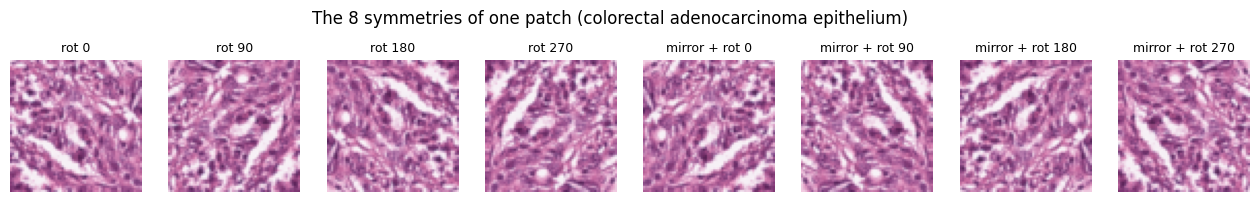

In [17]:
# The 8 symmetries of the square, as functions on a batch of images with shape (batch, channels, height, width).
SYMMETRIES = {
    f"{'mirror + ' if mirror else ''}rot {90 * k}": (
        lambda x, k=k, mirror=mirror: torch.rot90(x.flip(3) if mirror else x, k, dims=(2, 3))
    )
    for mirror in (False, True)
    for k in range(4)
}


def random_symmetry(x: torch.Tensor) -> torch.Tensor:
    # Augmentation: applies one of the 8 symmetries, chosen at random for each image, to a batch (N, C, H, W).
    mirror = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(mirror[:, None, None, None], x.flip(3), x)
    k = torch.randint(4, (len(x),), device=x.device)
    out = x.clone()
    for r in range(1, 4):
        out[k == r] = torch.rot90(x[k == r], r, dims=(2, 3))
    return out


# One OOD validation patch under the 8 symmetries
X, y = SPLITS["ood_val"]
patch = X[:1].float().div(255)
fig, axs = plt.subplots(1, len(SYMMETRIES), figsize=(16, 2.4))
for ax, (name, fn) in zip(axs, SYMMETRIES.items()):
    ax.imshow(fn(patch)[0].permute(1, 2, 0).numpy())
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.suptitle(f"The 8 symmetries of one patch ({CLASSES[y[0].item()]})", fontsize=12)
plt.show()

Balanced accuracy on ood_val under each symmetry (rot 0 is the original patch):


,MLP,SmallCNN
rot 0,0.574,0.834
rot 90,0.562,0.850
rot 180,0.569,0.841
rot 270,0.558,0.852
mirror + rot 0,0.561,0.853
mirror + rot 90,0.561,0.840
mirror + rot 180,0.567,0.850
mirror + rot 270,0.553,0.844


  loss w.r.t. rot 0, mean over the 7 symmetries: {'MLP': 0.012, 'SmallCNN': -0.013}
  loss w.r.t. rot 0, worst symmetry:             {'MLP': 0.021, 'SmallCNN': -0.006}

Balanced accuracy on id_val under each symmetry (rot 0 is the original patch):


,MLP,SmallCNN
rot 0,0.661,0.981
rot 90,0.647,0.970
rot 180,0.660,0.951
rot 270,0.648,0.963
mirror + rot 0,0.650,0.977
mirror + rot 90,0.654,0.961
mirror + rot 180,0.651,0.954
mirror + rot 270,0.651,0.975


  loss w.r.t. rot 0, mean over the 7 symmetries: {'MLP': 0.009, 'SmallCNN': 0.017}
  loss w.r.t. rot 0, worst symmetry:             {'MLP': 0.014, 'SmallCNN': 0.03}

rot 0 reproduces the Experiment 1 OOD balanced accuracy: True


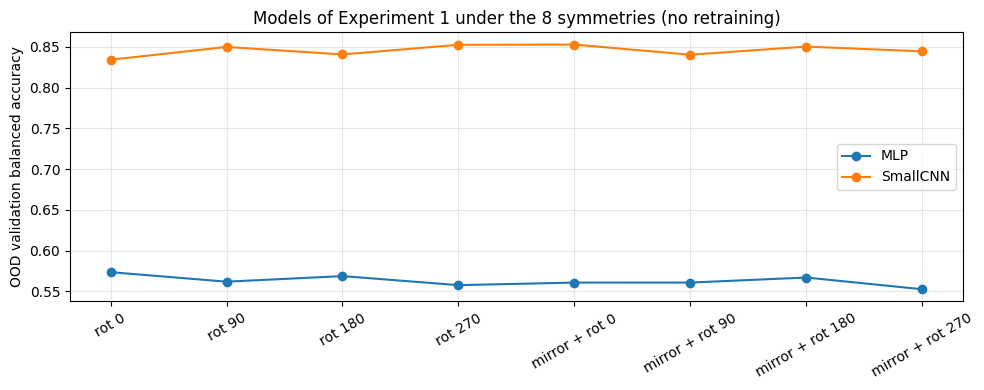

In [18]:
# Part (i): evaluate the models of Experiment 1, WITHOUT retraining, under the 8 symmetries.
def balanced_accuracy_under_symmetries(model: nn.Module, split: str, preprocess: Preprocess = rgb) -> pd.Series:
    # Balanced accuracy of a trained model on `split`, with every patch transformed by each of the 8 symmetries.
    loader = make_loader(split)
    return pd.Series({name: evaluate(model, loader, preprocess, input_fn=fn)["bal_acc"]
                      for name, fn in SYMMETRIES.items()})

exp1_models = {"MLP": MODELS["MLP (Exp. 1)"][0], "SmallCNN": MODELS["SmallCNN (Exp. 1)"][0]}
sym_exp1 = {split: pd.DataFrame({label: balanced_accuracy_under_symmetries(model, split)
                                 for label, model in exp1_models.items()})
            for split in ["ood_val", "id_val"]}

for split, table in sym_exp1.items():
    print(f"Balanced accuracy on {split} under each symmetry (rot 0 is the original patch):")
    display(table.round(3))
    drop = table.loc["rot 0"] - table.drop(index="rot 0")          # loss with respect to the original orientation
    print(f"  loss w.r.t. rot 0, mean over the 7 symmetries: {drop.mean().round(3).to_dict()}")
    print(f"  loss w.r.t. rot 0, worst symmetry:             {drop.max().round(3).to_dict()}\n")

# rot 0 is the identity, so it must reproduce the numbers that report() stored in Experiment 1
print("rot 0 reproduces the Experiment 1 OOD balanced accuracy:",
      all(abs(sym_exp1["ood_val"].loc["rot 0", label] - RESULTS[f"{label} (Exp. 1)"]["ood_bal_acc"]) < 1e-6
          for label in exp1_models))

fig, ax = plt.subplots(figsize=(10, 4))
for label, color in [("MLP", "tab:blue"), ("SmallCNN", "tab:orange")]:
    ax.plot(sym_exp1["ood_val"][label], "o-", color=color, label=label)
ax.set_ylabel("OOD validation balanced accuracy")
ax.set_title("Models of Experiment 1 under the 8 symmetries (no retraining)")
ax.tick_params(axis="x", rotation=30)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# Part (ii): the same models and the same training as in Experiment 1. The ONLY change is augment=random_symmetry:
# same seed before creating each model, same optimizer, learning rate, number of epochs and batch size, and the same
# order of batches (the loader is created again with the same seed).
torch.manual_seed(seed)
mlp_sym = MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=dropout).to(DEVICE)
mlp_sym_history = fit(mlp_sym, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                      optim.Adam(mlp_sym.parameters(), lr=learning_rate), n_epochs, rgb, augment=random_symmetry)
report("MLP + symmetries (Exp. 2)", mlp_sym, rgb, mlp_sym_history);

torch.manual_seed(seed)
cnn_sym = SmallCNN().to(DEVICE)
cnn_sym_history = fit(cnn_sym, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                      optim.Adam(cnn_sym.parameters(), lr=learning_rate), n_epochs, rgb, augment=random_symmetry)
report("SmallCNN + symmetries (Exp. 2)", cnn_sym, rgb, cnn_sym_history);

# The new models under the 8 symmetries, as in part (i)
exp2_models = {"MLP + symmetries": mlp_sym, "SmallCNN + symmetries": cnn_sym}
sym_exp2 = {split: pd.DataFrame({label: balanced_accuracy_under_symmetries(model, split)
                                 for label, model in exp2_models.items()})
            for split in ["ood_val", "id_val"]}
for split, table in sym_exp2.items():
    print(f"Balanced accuracy on {split} under each symmetry, models trained with the symmetries:")
    display(table.round(3))
    print(f"  spread (best - worst symmetry): {(table.max() - table.min()).round(3).to_dict()}\n")


epoch  1/10 | train loss 1.1845 | train acc 0.552 | val acc 0.536 | val bal. acc 0.520 *
epoch  2/10 | train loss 0.9645 | train acc 0.629 | val acc 0.644 | val bal. acc 0.633 *
epoch  3/10 | train loss 0.9045 | train acc 0.656 | val acc 0.631 | val bal. acc 0.623
epoch  4/10 | train loss 0.8701 | train acc 0.671 | val acc 0.657 | val bal. acc 0.659 *
epoch  5/10 | train loss 0.8396 | train acc 0.683 | val acc 0.686 | val bal. acc 0.682 *
epoch  6/10 | train loss 0.8143 | train acc 0.692 | val acc 0.684 | val bal. acc 0.668
epoch  7/10 | train loss 0.8013 | train acc 0.699 | val acc 0.689 | val bal. acc 0.682 *
epoch  8/10 | train loss 0.7747 | train acc 0.711 | val acc 0.705 | val bal. acc 0.693 *
epoch  9/10 | train loss 0.7599 | train acc 0.717 | val acc 0.707 | val bal. acc 0.700 *
epoch 10/10 | train loss 0.7488 | train acc 0.723 | val acc 0.705 | val bal. acc 0.703 *
MLP + symmetries (Exp. 2): ID bal. acc 0.703 | OOD bal. acc 0.579 | gap +0.124 | ID acc 0.705 | OOD acc 0.641
epoc

,MLP + symmetries,SmallCNN + symmetries
rot 0,0.579,0.888
rot 90,0.587,0.904
rot 180,0.578,0.886
rot 270,0.580,0.904
mirror + rot 0,0.573,0.892
mirror + rot 90,0.573,0.883
mirror + rot 180,0.575,0.889
mirror + rot 270,0.571,0.888


  spread (best - worst symmetry): {'MLP + symmetries': 0.016, 'SmallCNN + symmetries': 0.021}

Balanced accuracy on id_val under each symmetry, models trained with the symmetries:


,MLP + symmetries,SmallCNN + symmetries
rot 0,0.703,0.982
rot 90,0.705,0.980
rot 180,0.707,0.981
rot 270,0.700,0.981
mirror + rot 0,0.703,0.981
mirror + rot 90,0.708,0.980
mirror + rot 180,0.704,0.981
mirror + rot 270,0.703,0.981


  spread (best - worst symmetry): {'MLP + symmetries': 0.008, 'SmallCNN + symmetries': 0.002}



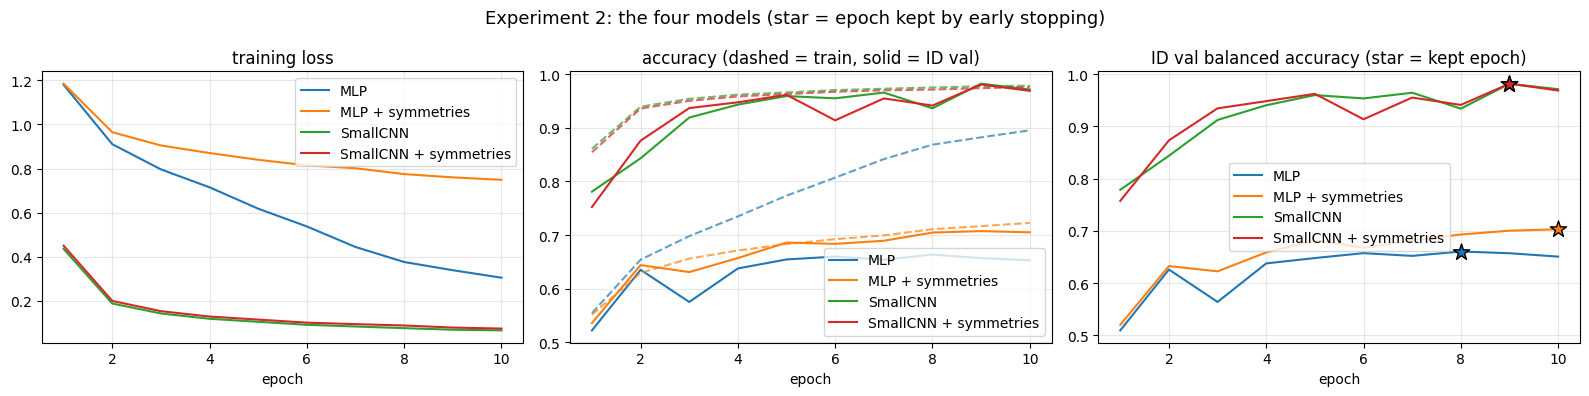

,ID bal. acc,OOD bal. acc,gap,"OOD, mean of the 8 symmetries","OOD, worst symmetry","OOD, best - worst","OOD, mean loss of the 7 symmetries",best epoch,train time (s)
MLP,0.661,0.574,0.087,0.563,0.553,0.021,0.012,8.0,38.0
MLP + symmetries,0.703,0.579,0.124,0.577,0.571,0.016,0.003,10.0,43.0
SmallCNN,0.981,0.834,0.147,0.846,0.834,0.019,-0.013,9.0,232.0
SmallCNN + symmetries,0.982,0.888,0.094,0.892,0.883,0.021,-0.005,9.0,233.0


MLP, with the symmetries as augmentation: ID 0.661 -> 0.703 | OOD 0.574 -> 0.579 (+0.006) | gap +0.087 -> +0.124 (+0.037)
SmallCNN, with the symmetries as augmentation: ID 0.981 -> 0.982 | OOD 0.834 -> 0.888 (+0.054) | gap +0.147 -> +0.094 (-0.053)


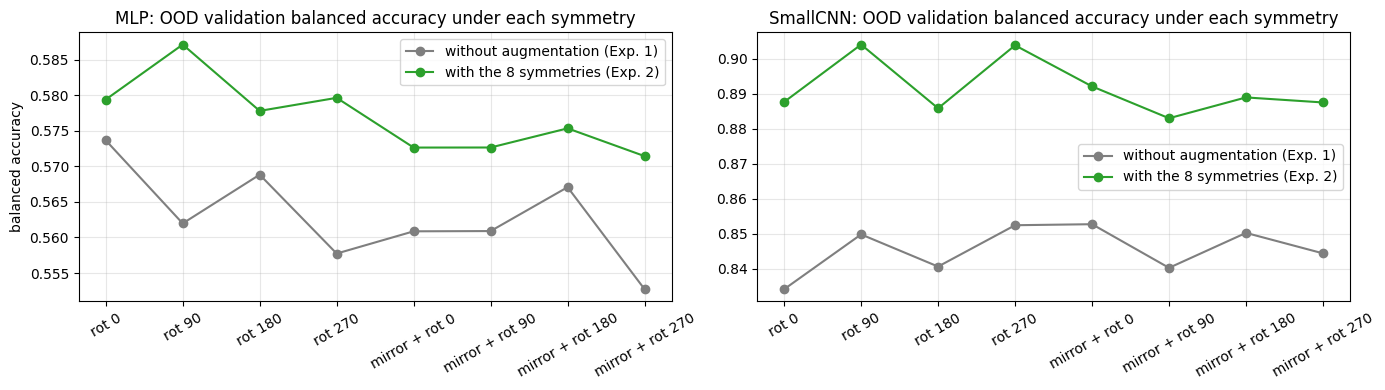

In [20]:
# Compare the four models: learning curves, metrics under each symmetry, ID and OOD balanced accuracy, gap.
ORDER = {"MLP": "MLP (Exp. 1)", "MLP + symmetries": "MLP + symmetries (Exp. 2)",
         "SmallCNN": "SmallCNN (Exp. 1)", "SmallCNN + symmetries": "SmallCNN + symmetries (Exp. 2)"}
histories_exp2 = {"MLP": mlp_history, "MLP + symmetries": mlp_sym_history,
                  "SmallCNN": cnn_history, "SmallCNN + symmetries": cnn_sym_history}

# 1. Learning curves
plot_histories(histories_exp2, "Experiment 2: the four models (star = epoch kept by early stopping)")

# 2. Metrics: ID, OOD, gap, and how much each model changes under the 8 symmetries (OOD validation)
sym_ood = pd.concat([sym_exp1["ood_val"], sym_exp2["ood_val"]], axis=1)[list(ORDER)]
rows = {}
for label, key in ORDER.items():
    r, s = RESULTS[key], sym_ood[label]
    rows[label] = {
        "ID bal. acc": r["id_bal_acc"], "OOD bal. acc": r["ood_bal_acc"], "gap": r["gap_bal_acc"],
        "OOD, mean of the 8 symmetries": s.mean(), "OOD, worst symmetry": s.min(),
        "OOD, best - worst": s.max() - s.min(),
        "OOD, mean loss of the 7 symmetries": (s["rot 0"] - s.drop("rot 0")).mean(),
        "best epoch": histories_exp2[label]["best_epoch"], "train time (s)": r["train_time_s"],
    }
display(pd.DataFrame(rows).T.round(3))

for arch in ["MLP", "SmallCNN"]:
    before, after = RESULTS[ORDER[arch]], RESULTS[ORDER[f"{arch} + symmetries"]]
    print(f"{arch}, with the symmetries as augmentation: "
          f"ID {before['id_bal_acc']:.3f} -> {after['id_bal_acc']:.3f} | "
          f"OOD {before['ood_bal_acc']:.3f} -> {after['ood_bal_acc']:.3f} "
          f"({after['ood_bal_acc'] - before['ood_bal_acc']:+.3f}) | "
          f"gap {before['gap_bal_acc']:+.3f} -> {after['gap_bal_acc']:+.3f} "
          f"({after['gap_bal_acc'] - before['gap_bal_acc']:+.3f})")

# 3. OOD balanced accuracy under each symmetry, without and with the augmentation
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, arch in zip(axs, ["MLP", "SmallCNN"]):
    ax.plot(sym_ood[arch], "o-", color="tab:gray", label="without augmentation (Exp. 1)")
    ax.plot(sym_ood[f"{arch} + symmetries"], "o-", color="tab:green", label="with the 8 symmetries (Exp. 2)")
    ax.set_title(f"{arch}: OOD validation balanced accuracy under each symmetry")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(alpha=0.3)
    ax.legend()
axs[0].set_ylabel("balanced accuracy")
plt.tight_layout()
plt.show()

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: what remained the same as in Experiment 1 and what changed. Why does
> evaluating a model on transformed copies of the same patches measure its invariance? Why is the augmentation the only
> difference between the two trainings of each architecture? How does your experiment answer the question?

### Resposta

**O que ficou igual ao Experimento 1.** Usei as mesmas arquiteturas (o MLP 512-256 sem dropout e a SmallCNN 32-64-128), os mesmos dados e splits, a mesma padronização e o mesmo loop `fit`, com Adam, learning rate 1e-3, 10 épocas e batches de 128. Fixei a mesma semente antes de criar cada modelo, então os modelos novos começam com os mesmos pesos iniciais dos do Experimento 1. Recriei o loader com a mesma semente, então a ordem dos batches também é a mesma, e o critério de early stopping continua sendo a acurácia balanceada na validação ID. Os modelos "sem augmentation" são os próprios do Experimento 1, sem retreinar.

**O que mudou.** Só o argumento `augment=random_symmetry` no treino: cada patch de treino recebe, toda vez que aparece, uma das 8 simetrias sorteada, aplicada antes da padronização. A validação não recebe augmentation.

**Por que avaliar cópias transformadas mede invariância.** As 8 simetrias não mudam a classe de um patch, porque o tecido não tem "cima", então um modelo invariante teria que acertar igual nas 8 versões. As cópias são as mesmas imagens, com os mesmos rótulos e a mesma mistura de classes, então qualquer mudança na acurácia balanceada vem só da transformação. A `rot 0` é a identidade e reproduz exatamente o número do Experimento 1 (conferi no código), então a perda em relação a ela mede a sensibilidade à orientação, e a diferença entre a melhor e a pior simetria mede o quanto o modelo varia. Avaliei na validação OOD, como a hipótese pedia, e também na ID, porque na OOD parte da variação pode ser ruído de uma mudança de aparência.

**Por que a augmentation é a única diferença entre os dois treinos de cada arquitetura.** Porque pareei tudo: mesmos pesos iniciais, mesma ordem de batches, mesmo otimizador, mesmas épocas e mesmo critério de parada. Uma ressalva é que isso vale para a configuração, não necessariamente para a causa: a augmentation também aumenta a variedade dos dados e age como regularizador, então este experimento não separa o efeito da invariância do efeito de regularização. Também é uma semente só.

**Como o experimento responde à pergunta.** A parte (i) responde se os modelos do Experimento 1 são invariantes, olhando a perda em relação a `rot 0` e a diferença entre a melhor e a pior simetria. A parte (ii) responde se a augmentation torna os modelos invariantes (a mesma diferença melhor-pior depois do treino) e se reduz o gap (OOD e gap antes e depois, para cada arquitetura). Comparar o MLP com a CNN mostra se o compartilhamento de pesos faz diferença.


### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of the symmetry experiment. Address the following points:
>
> Were the models of Experiment 1 invariant to the symmetries? Did the MLP and the CNN behave differently? Refer to
> specific numbers.
>
> Did augmentation make each architecture invariant? Did it help the CNN and the MLP equally? Relate your answer to the
> sentence from Lecture 18 quoted above.
>
> Did augmentation change the ID–OOD gap? Augmentation also acts as a regularizer, because the model rarely sees
> exactly the same image twice. Can you attribute the change in OOD performance to the invariance itself, rather than
> to less overfitting?

### Resposta

**Os modelos do Experimento 1 eram invariantes?** Quase, e a parte (i) da minha hipótese foi contradita. Na validação OOD, o MLP teve 0,574 em rot 0 e entre 0,553 e 0,569 nas outras 7 simetrias (perda média de 0,012, pior caso 0,021). A CNN teve 0,834 em rot 0 e entre 0,840 e 0,853 nas outras 7, ou seja, não perdeu nada: ganhou 0,013 em média, e a orientação original foi a pior das 8. Então a CNN não perdeu os 0,02 que eu previ, e o MLP perdeu mais que ela, o contrário do que escrevi. Na validação ID, que é mais limpa porque não tem a troca de centro, o padrão é o que eu previa: o MLP perde em média 0,009 (pior 0,014) e a CNN 0,017 (pior 0,030, em rot 180, de 0,981 para 0,951). Mesmo assim as perdas são de poucos pontos, então os dois já são quase invariantes sem augmentation. Meu palpite é que, como o tecido não tem "cima", o próprio treino já tem patches em várias orientações. Também acho que na OOD a variação entre simetrias (0,834 a 0,853) é do tamanho do ruído, porque o erro ali é dominado pela mudança de aparência, então a OOD sozinha não mede invariância com essa precisão.

**A augmentation tornou os modelos invariantes? Ajudou igual?** Na ID sim: a diferença entre a melhor e a pior simetria caiu de 0,030 para 0,002 na CNN e de 0,014 para 0,008 no MLP. Na OOD o MLP foi de 0,021 para 0,016 e a CNN ficou em 0,021 (antes 0,019), um pouco acima do meu limite de 0,02, mas isso parece ruído. Não ajudou igual. Na CNN a OOD subiu de 0,834 para 0,888 (+0,054), a ID ficou praticamente igual (0,981 para 0,982) e o gap caiu de +0,147 para +0,094. No MLP a ID subiu de 0,661 para 0,703 (+0,042), mas a OOD foi de 0,574 para 0,579 (+0,006) e o gap aumentou, de +0,087 para +0,124. A parte (ii) da hipótese se confirmou: a OOD e o gap da CNN melhoraram, e a OOD do MLP não subiu mais que 0,02. Isso combina com a frase da Aula 18, que diz que a convolução dá a capacidade de detectar um padrão em qualquer lugar e a augmentation ensina a usá-la. Na CNN os filtros são compartilhados, então, vendo as 8 versões, o mesmo filtro aprende o padrão em todas as orientações. O MLP não compartilha pesos e a augmentation só o regulariza: a acurácia de treino caiu de 0,895 para 0,723, quase igual à de validação (0,705), ele parou de decorar o treino e melhorou no ID, mas isso não chegou ao novo centro. Uma ressalva é que a validação do MLP ainda subia na época 10 (a melhor época foi a última), então com mais épocas ele poderia melhorar mais.

**O gap mudou, e dá para atribuir à invariância?** O gap da CNN caiu 0,053 e o do MLP subiu 0,037, porque no MLP o ID subiu e a OOD não. Não consigo atribuir o ganho da CNN à invariância em si. A CNN já era quase invariante (na OOD nem perdia com as simetrias), então corrigir a sensibilidade à orientação não explica um ganho de 0,054. Também não parece ser menos overfitting no sentido comum, porque a CNN não fazia overfitting no ID: a acurácia de treino (0,978 para 0,976) e a de validação ID (0,981 para 0,982) ficaram iguais. O MLP mostra que só regularizar não leva à OOD: o dropout do Experimento 1 (OOD de 0,574 para 0,578) e esta augmentation (de 0,574 para 0,579) deixaram a OOD dele praticamente parada. Na CNN a augmentation melhorou só a OOD, o que sugere que depende de a arquitetura reaproveitar os padrões nas várias orientações, mas isso é um palpite, não uma prova. Para separar as duas explicações faltaria um controle, como uma augmentation que não seja simetria da tarefa, ou um regularizador como dropout ou weight decay na CNN. Faltam também várias sementes: a mesma CNN varia de 0,834 a 0,853 só com a orientação, então eu só trato como real uma diferença bem maior que isso. O Experimento 4 mede o ruído entre sementes.


---

## Experiment 3: Is the Stain Color a Shortcut?

Each center has its own staining protocol and scanner, so the colors of a patch partly encode **where** it was
acquired. A network trained on a single center may learn to recognize a tissue by the exact shades it has in that
center, a **shortcut** that fits the training data but does not transfer to a center whose stains look different,
even if the morphology of the tissue is the same.

There are two opposite ways to prevent a network from relying on the exact colors:
- **remove them**: train and evaluate on grayscale patches. The network cannot use color at all, but it also loses
  the difference between the purple of hematoxylin (nuclei) and the pink of eosin (cytoplasm, fibers), which a
  pathologist uses;
- **randomize them**: keep the colors, but change the amount of each stain at random in every training patch
  (**stain augmentation**, Tellez et al., 2019), so that no exact shade is reliably associated with a class.

`stain_jitter` below converts each RGB patch into the concentrations of hematoxylin, eosin and DAB (the color
deconvolution of `skimage.color.rgb2hed`), multiplies each concentration by a random factor in [1 − `scale`,
1 + `scale`], adds a random shift in [−`shift`, `shift`], and converts back to RGB. Every patch gets its own factors.

> **Question:**
>
> Does the CNN rely on the exact stain colors of the training center? Which strategy reduces the ID–OOD gap more:
> removing color (grayscale) or randomizing the stains during training (stain augmentation)?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis. It should predict the direction of the change in ID balanced accuracy, OOD
> balanced accuracy and ID–OOD gap for each of the two strategies, relative to the CNN of the previous experiments, and
> which strategy is better. Consider both what color reveals about the center and what it reveals about the tissue,
> and relate your prediction to the Data Exploration.*

### Resposta

**Referência.** Todas as mudanças são em relação à SmallCNN do Experimento 1 (ID 0,981, OOD 0,834, gap +0,147), assim só a cor muda.

**O que a cor diz sobre o centro e sobre o tecido (Exploração).** Sobre o centro: um classificador não linear distingue os dois centros só pela cor do patch (AUC 0,826 com a cor média e 0,890 com média e desvio), e a última camada da CNN também carrega o centro (AUC 0,939), então a cor é um possível atalho. Sobre o tecido: a distância média de cor entre duas classes (49,9) é bem maior que o deslocamento de uma classe entre os centros (14,6), então a cor também informa o tecido, e isso vale nos dois centros (adipose e background se reconhecem pela cor).

**Hipótese.**
- **Escala de cinza:** a ID cai pelo menos 0,01, porque joga fora o matiz que ajuda a separar tecidos. A OOD sobe e o gap cai, mas menos que na stain augmentation, porque a luminosidade continua mudando entre os centros (no novo centro o adipose fica mais claro e o background mais escuro).
- **Stain augmentation:** a ID fica praticamente igual (variação de no máximo 0,01), porque as cores continuam plausíveis e a informação de cor útil para o tecido é mantida. A OOD sobe pelo menos 0,03 e o gap cai.
- **Melhor estratégia:** a stain augmentation, com OOD maior e gap menor que a escala de cinza. Se isso acontecer, a CNN usa sim o tom exato das colorações do centro de treino.

**Como pode ser contradita.** Se a OOD da escala de cinza for maior ou igual à da stain augmentation, ou se o gap dela for menor ou igual. Também se a stain augmentation subir a OOD menos de 0,03 ou derrubar a ID em mais de 0,01, se a ID da escala de cinza não cair 0,01, ou se nenhuma das duas reduzir o gap abaixo de +0,147. Como é uma semente só, o Experimento 4 mede o ruído.


In [21]:
# (a) Grayscale: the same gray image in the 3 channels (so the architecture does not change), standardized with
#     statistics of the grayscale training split. Used for training AND evaluation.
def grayscale(x: torch.Tensor) -> torch.Tensor:
    gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
    return gray.expand(-1, 3, -1, -1)


gray = Preprocess(color_fn=grayscale)


# (b) Stain augmentation, for the TRAINING split only (the model is evaluated with `rgb`).
RGB_FROM_HED = torch.tensor([[0.65, 0.70, 0.29],    # hematoxylin
                             [0.07, 0.99, 0.11],    # eosin
                             [0.27, 0.57, 0.78]])   # DAB      (the matrix of skimage.color.rgb2hed)
HED_FROM_RGB = torch.linalg.inv(RGB_FROM_HED)


def stain_jitter(x: torch.Tensor, scale: float = 0.2, shift: float = 0.05) -> torch.Tensor:
    # Random change of the amount of each stain, with its own factors for each image of a batch (N, 3, H, W) in [0, 1].
    optical_density = -torch.log(x.clamp(min=1e-6)).permute(0, 2, 3, 1)           # (N, H, W, 3)
    stains = optical_density @ HED_FROM_RGB.to(x.device)                         # concentrations of H, E and DAB
    factors = 1 + scale * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    shifts = shift * (2 * torch.rand(len(x), 1, 1, 3, device=x.device) - 1)
    stains = stains * factors + shifts
    return torch.exp(-(stains @ RGB_FROM_HED.to(x.device))).clamp(0, 1).permute(0, 3, 1, 2)


# Choose the strength of the augmentation and justify it: the default values are only a starting point.
# Example of use: fit(..., preprocess=rgb, augment=stain_jitter). If you start from Experiment 2, combine both:
# augment=lambda x: random_symmetry(stain_jitter(x)).

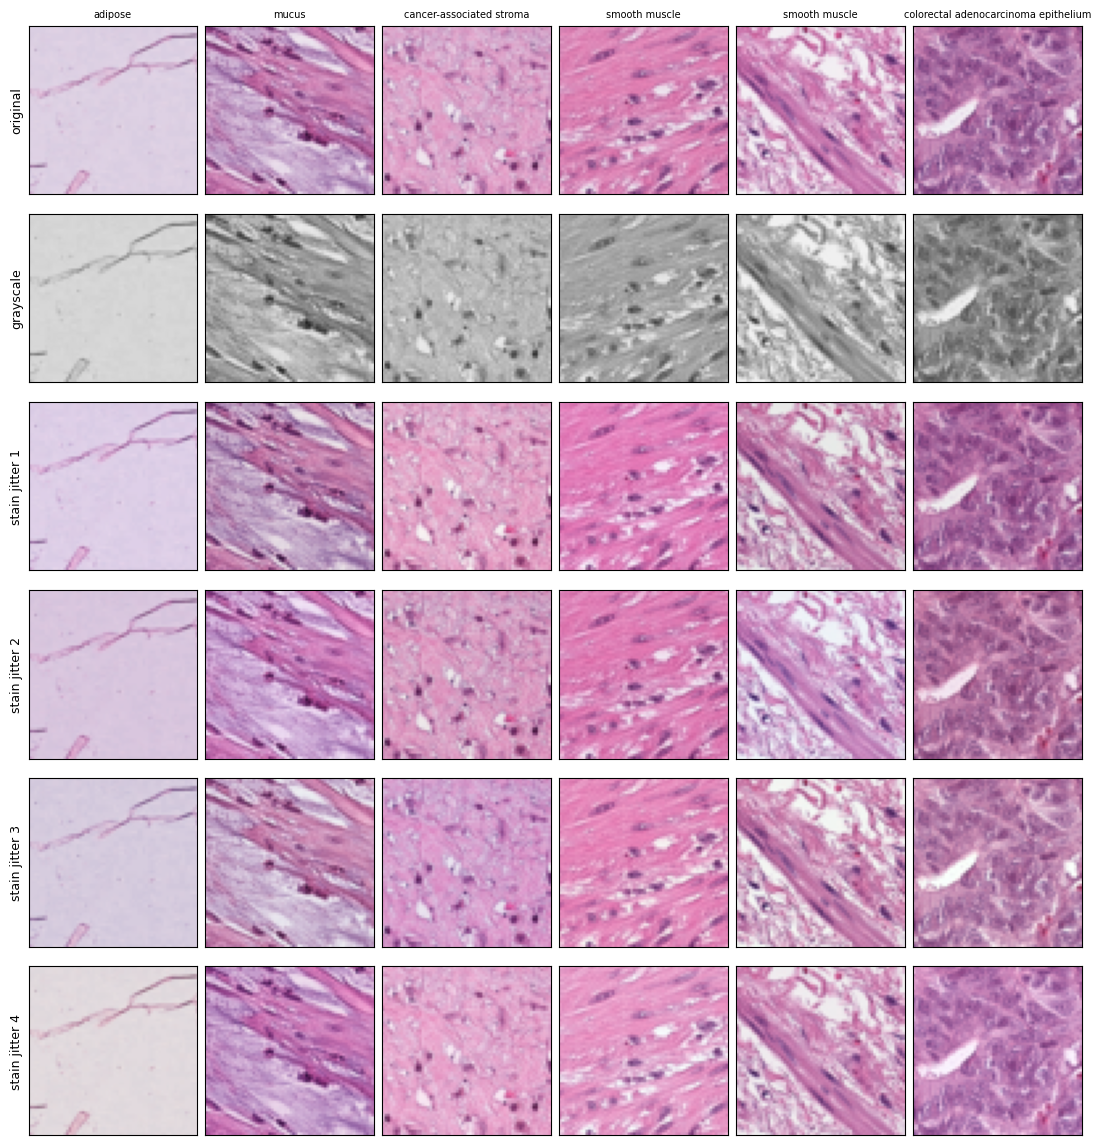

In [22]:
# The same training patches: original, grayscale and four draws of stain augmentation
X, y = SPLITS["train"]
patches = X[:6].float().div(255)
torch.manual_seed(seed)
rows = {"original": patches, "grayscale": grayscale(patches)}
rows.update({f"stain jitter {k + 1}": stain_jitter(patches) for k in range(4)})

fig, axs = plt.subplots(len(rows), len(patches), figsize=(1.8 * len(patches), 1.9 * len(rows)), constrained_layout=True)
for i, (name, batch) in enumerate(rows.items()):
    for j in range(len(patches)):
        axs[i, j].imshow(batch[j].permute(1, 2, 0).numpy())
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        if i == 0:
            axs[i, j].set_title(CLASSES[y[j].item()], fontsize=7)
    axs[i, 0].set_ylabel(name, fontsize=9)
plt.show()

,,mean color change,90th percentile,% of the distance between classes
scale,shift,,,
0.1,0.02,4.73,8.08,9.48
0.2,0.05,10.35,17.55,20.75
0.3,0.08,16.00,27.22,32.06
0.5,0.15,28.14,48.42,56.39
0.7,0.20,38.05,64.62,76.26


Mean color distance between two different classes, inside the training center: 49.9


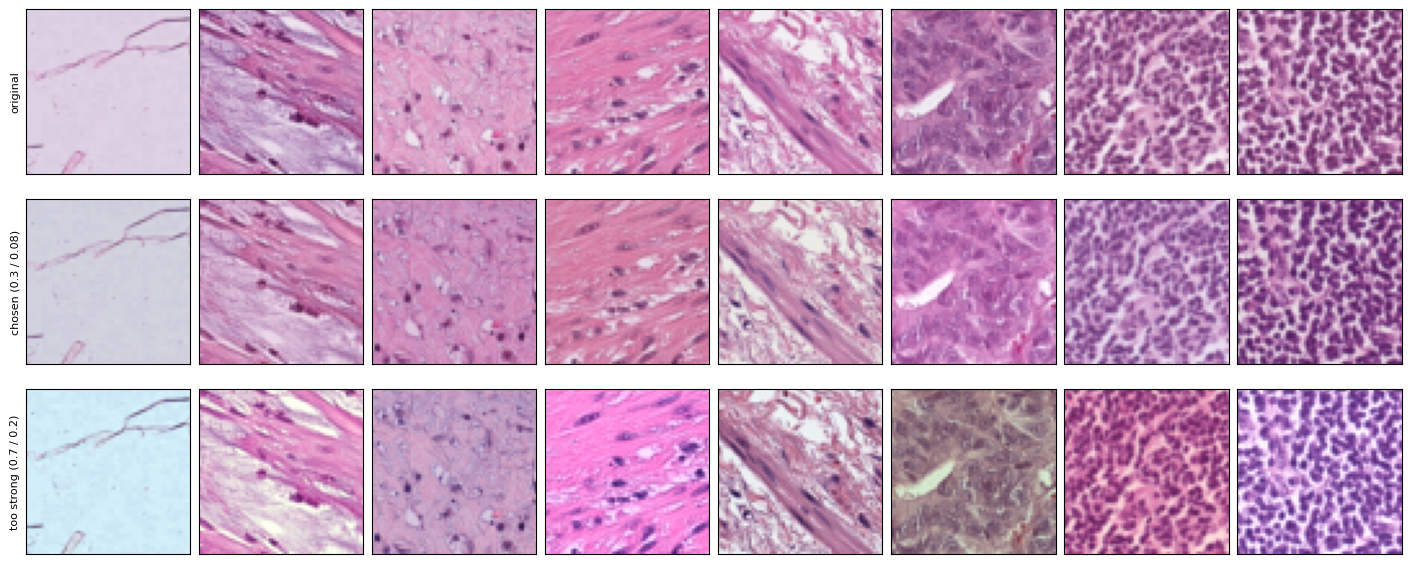

epoch  1/10 | train loss 0.6710 | train acc 0.771 | val acc 0.818 | val bal. acc 0.831 *
epoch  2/10 | train loss 0.3779 | train acc 0.870 | val acc 0.853 | val bal. acc 0.850 *
epoch  3/10 | train loss 0.3038 | train acc 0.897 | val acc 0.815 | val bal. acc 0.820
epoch  4/10 | train loss 0.2600 | train acc 0.912 | val acc 0.844 | val bal. acc 0.851 *
epoch  5/10 | train loss 0.2368 | train acc 0.920 | val acc 0.893 | val bal. acc 0.889 *
epoch  6/10 | train loss 0.2136 | train acc 0.928 | val acc 0.908 | val bal. acc 0.904 *
epoch  7/10 | train loss 0.1968 | train acc 0.935 | val acc 0.920 | val bal. acc 0.919 *
epoch  8/10 | train loss 0.1870 | train acc 0.938 | val acc 0.895 | val bal. acc 0.885
epoch  9/10 | train loss 0.1755 | train acc 0.942 | val acc 0.929 | val bal. acc 0.928 *
epoch 10/10 | train loss 0.1644 | train acc 0.945 | val acc 0.917 | val bal. acc 0.919
SmallCNN, grayscale (Exp. 3): ID bal. acc 0.928 | OOD bal. acc 0.832 | gap +0.096 | ID acc 0.929 | OOD acc 0.863
epo

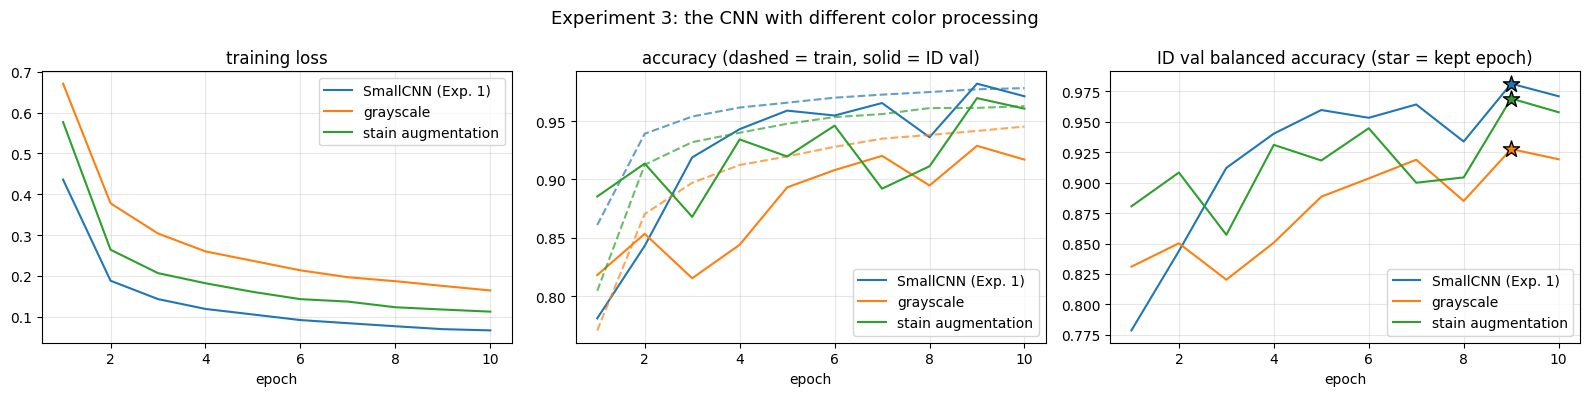

,ID bal. acc,OOD bal. acc,gap,ID vs Exp. 1,OOD vs Exp. 1,gap vs Exp. 1,ID acc,OOD acc,train time (s)
SmallCNN (Exp. 1),0.981,0.834,0.147,0.000,0.000,0.000,0.982,0.858,232.0
grayscale,0.928,0.832,0.096,-0.054,-0.003,-0.051,0.929,0.863,232.0
stain augmentation,0.969,0.893,0.076,-0.012,0.059,-0.071,0.970,0.925,198.0
symmetries (Exp. 2),0.982,0.888,0.094,0.000,0.054,-0.053,0.981,0.899,233.0


Recall of each class on the OOD validation split, and its change with respect to the SmallCNN of Exp. 1:


,SmallCNN (Exp. 1),grayscale,stain augmentation,symmetries (Exp. 2),grayscale: change,stain augmentation: change,symmetries (Exp. 2): change
adipose,0.949,0.946,0.993,0.991,-0.003,0.043,0.042
background,1.000,1.000,1.000,1.000,0.000,0.000,0.000
debris,0.971,0.888,0.835,0.965,-0.082,-0.135,-0.006
lymphocytes,0.896,0.830,0.987,0.991,-0.066,0.091,0.095
mucus,0.604,0.894,0.867,0.693,0.290,0.263,0.089
smooth muscle,0.868,0.733,0.980,0.804,-0.135,0.111,-0.064
normal mucosa,0.922,0.854,0.881,0.932,-0.068,-0.041,0.011
stroma,0.338,0.481,0.510,0.671,0.143,0.171,0.333
tumor,0.959,0.859,0.982,0.942,-0.101,0.023,-0.018


grayscale: loses most in smooth muscle (-0.14) and gains most in mucus (+0.29)
stain augmentation: loses most in debris (-0.14) and gains most in mucus (+0.26)
Recall of each class on the ID validation split, and its change with respect to the SmallCNN of Exp. 1:


,SmallCNN (Exp. 1),grayscale,stain augmentation,symmetries (Exp. 2),grayscale: change,stain augmentation: change,symmetries (Exp. 2): change
adipose,0.998,0.985,0.989,0.997,-0.013,-0.009,-0.001
background,0.999,0.997,0.996,1.000,-0.002,-0.003,0.001
debris,0.982,0.957,0.959,0.969,-0.024,-0.023,-0.013
lymphocytes,0.987,0.991,0.982,0.993,0.004,-0.005,0.006
mucus,0.962,0.946,0.983,0.978,-0.016,0.021,0.016
smooth muscle,0.991,0.950,0.951,0.965,-0.041,-0.040,-0.026
normal mucosa,0.986,0.865,0.940,0.982,-0.121,-0.047,-0.005
stroma,0.946,0.767,0.937,0.987,-0.179,-0.010,0.040
tumor,0.981,0.890,0.985,0.964,-0.091,0.004,-0.017


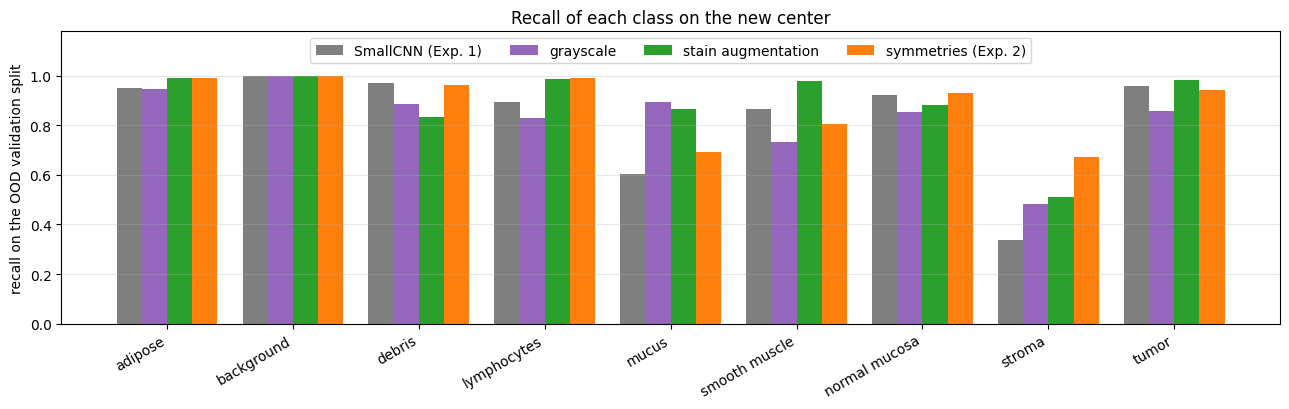

AUC of telling ID from OOD patches with the last hidden layer (0.5 = the center is invisible): {'SmallCNN (Exp. 1)': np.float64(0.939), 'grayscale': np.float64(0.839), 'stain augmentation': np.float64(0.926)}


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Starting point: the SmallCNN configuration of Experiment 1 (Adam, learning_rate, n_epochs, batch size 128, same seed
# and same order of batches, no other augmentation). The ONLY change is the color processing.

# ── Strength of the stain augmentation ──────────────────────────────────────────────────────────────────────────
# Chosen with the TRAINING split only (ood_val plays no role in this choice). Criterion: the jitter must change the
# color of a patch by a visible amount, but clearly less than the color distance between two tissue classes, so that
# color keeps telling the tissues apart (a much stronger jitter would turn into the grayscale strategy).
def color_of(x01: torch.Tensor) -> torch.Tensor:
    # Mean RGB (0-255) of each patch of a batch with values in [0, 1].
    return x01.mean(dim=(2, 3)).mul(255).cpu()

train_color = torch.cat([color_of(to_unit(X_train[i:i + 5_000])) for i in range(0, len(X_train), 5_000)])
class_color = torch.stack([torch.quantile(train_color[y_train == c], 0.5, dim=0) for c in range(len(CLASSES))])
between_class = torch.pdist(class_color).mean().item()    # mean color distance between two classes (training center)

calib = to_unit(X_train[:2_000])
rows = []
for scale, shift in [(0.1, 0.02), (0.2, 0.05), (0.3, 0.08), (0.5, 0.15), (0.7, 0.2)]:
    torch.manual_seed(seed)
    change = (color_of(stain_jitter(calib, scale, shift)) - color_of(calib)).norm(dim=1)   # color change of each patch
    rows.append({"scale": scale, "shift": shift, "mean color change": change.mean().item(),
                 "90th percentile": change.quantile(0.9).item(),
                 "% of the distance between classes": 100 * change.mean().item() / between_class})
display(pd.DataFrame(rows).round(2).set_index(["scale", "shift"]))
print(f"Mean color distance between two different classes, inside the training center: {between_class:.1f}")

torch.manual_seed(seed)
examples = {"original": calib[:8],
            "chosen (0.3 / 0.08)": stain_jitter(calib[:8], 0.3, 0.08),
            "too strong (0.7 / 0.2)": stain_jitter(calib[:8], 0.7, 0.2)}
fig, axs = plt.subplots(len(examples), 8, figsize=(14, 1.9 * len(examples)), constrained_layout=True)
for r, (name, batch) in enumerate(examples.items()):
    for j in range(8):
        axs[r, j].imshow(batch[j].permute(1, 2, 0).cpu().numpy())
        axs[r, j].set_xticks([])
        axs[r, j].set_yticks([])
    axs[r, 0].set_ylabel(name, fontsize=8)
plt.show()

# Chosen: the strongest setting of the table whose mean color change is about a third of the distance between classes
# and whose 90th percentile stays below that distance. In the figure it still looks like H&E, and the 0.7 / 0.2 does not.
STAIN_SCALE, STAIN_SHIFT = 0.3, 0.08

def stain_augment(x: torch.Tensor) -> torch.Tensor:
    return stain_jitter(x, scale=STAIN_SCALE, shift=STAIN_SHIFT)

# ── (a) Grayscale: trained and evaluated on gray patches (`gray`) ───────────────────────────────────────────────
torch.manual_seed(seed)
cnn_gray = SmallCNN().to(DEVICE)
cnn_gray_history = fit(cnn_gray, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                       optim.Adam(cnn_gray.parameters(), lr=learning_rate), n_epochs, gray)
report("SmallCNN, grayscale (Exp. 3)", cnn_gray, gray, cnn_gray_history);

# ── (b) Stain augmentation: trained with stain_jitter, evaluated on the original colors (`rgb`) ─────────────────
torch.manual_seed(seed)
cnn_stain = SmallCNN().to(DEVICE)
cnn_stain_history = fit(cnn_stain, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                        optim.Adam(cnn_stain.parameters(), lr=learning_rate), n_epochs, rgb, augment=stain_augment)
report("SmallCNN + stain augmentation (Exp. 3)", cnn_stain, rgb, cnn_stain_history);

# ── Analysis ─────────────────────────────────────────────────────────────────────────────────────────────────────
COMPARE = {"SmallCNN (Exp. 1)": "SmallCNN (Exp. 1)", "grayscale": "SmallCNN, grayscale (Exp. 3)",
           "stain augmentation": "SmallCNN + stain augmentation (Exp. 3)"}
if "SmallCNN + symmetries (Exp. 2)" in RESULTS:     # an augmentation that does not touch the color, as a reference
    COMPARE["symmetries (Exp. 2)"] = "SmallCNN + symmetries (Exp. 2)"
base = RESULTS["SmallCNN (Exp. 1)"]

# 1. Learning curves and metrics
plot_histories({"SmallCNN (Exp. 1)": cnn_history, "grayscale": cnn_gray_history,
                "stain augmentation": cnn_stain_history}, "Experiment 3: the CNN with different color processing")
metrics = {}
for label, key in COMPARE.items():
    r = RESULTS[key]
    metrics[label] = {"ID bal. acc": r["id_bal_acc"], "OOD bal. acc": r["ood_bal_acc"], "gap": r["gap_bal_acc"],
                      "ID vs Exp. 1": r["id_bal_acc"] - base["id_bal_acc"],
                      "OOD vs Exp. 1": r["ood_bal_acc"] - base["ood_bal_acc"],
                      "gap vs Exp. 1": r["gap_bal_acc"] - base["gap_bal_acc"],
                      "ID acc": r["id_acc"], "OOD acc": r["ood_acc"], "train time (s)": r["train_time_s"]}
display(pd.DataFrame(metrics).T.round(3))

# 2. Recall of each class: which classes gain or lose with each strategy
SHORT3 = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle", "normal mucosa", "stroma", "tumor"]

def class_recalls(key: str, split: str) -> np.ndarray:
    model, prep = MODELS[key]
    pred, true = predict(model, make_loader(split), prep)
    return np.array([(pred[true == c] == c).mean() for c in range(len(CLASSES))])

recall = {split: pd.DataFrame({label: class_recalls(key, split) for label, key in COMPARE.items()}, index=SHORT3)
          for split in ["id_val", "ood_val"]}
for split, title in [("ood_val", "OOD"), ("id_val", "ID")]:
    print(f"Recall of each class on the {title} validation split, and its change with respect to the SmallCNN of Exp. 1:")
    table = recall[split]
    change_vs_base = table.drop(columns="SmallCNN (Exp. 1)").sub(table["SmallCNN (Exp. 1)"], axis=0)
    change_vs_base.columns = [f"{c}: change" for c in change_vs_base.columns]
    display(pd.concat([table, change_vs_base], axis=1).round(3))
    if split == "ood_val":
        for label in ["grayscale", "stain augmentation"]:
            s = (table[label] - table["SmallCNN (Exp. 1)"]).sort_values()
            print(f"{label}: loses most in {s.index[0]} ({s.iloc[0]:+.2f}) and gains most in {s.index[-1]} ({s.iloc[-1]:+.2f})")

fig, ax = plt.subplots(figsize=(13, 4.2))
width = 0.8 / len(COMPARE)
for k, (label, color) in enumerate(zip(COMPARE, ["tab:gray", "tab:purple", "tab:green", "tab:orange"])):
    ax.bar(np.arange(len(SHORT3)) + (k - (len(COMPARE) - 1) / 2) * width, recall["ood_val"][label], width=width,
           color=color, label=label)
ax.set_xticks(range(len(SHORT3)))
ax.set_xticklabels(SHORT3, rotation=30, ha="right")
ax.set_ylabel("recall on the OOD validation split")
ax.set_title("Recall of each class on the new center")
ax.set_ylim(0, 1.18)                                  # free band at the top, so that the legend hides no bar
ax.grid(alpha=0.3, axis="y")
ax.legend(ncol=len(COMPARE), loc="upper center")
plt.tight_layout()
plt.show()

# 3. Is the center still visible in the last hidden layer? Same patches and same test as in Experiment 1
# (ID and OOD patches with the same class mix; logistic regression, 5-fold cross-validation, AUC 0.5 = invisible).
rng_c = np.random.default_rng(seed)
ood_pick = rng_c.choice(len(y_ood_val), 2_000, replace=False)
id_pick = np.concatenate([
    rng_c.choice(np.flatnonzero(y_id_val.numpy() == c), size=int((y_ood_val[ood_pick] == c).sum()), replace=False)
    for c in range(len(CLASSES))
])
center_X = torch.cat([X_id_val[id_pick], X_ood_val[ood_pick]])
center_y = np.r_[np.zeros(len(id_pick)), np.ones(len(ood_pick))]

@torch.no_grad()
def last_hidden_features(model: nn.Module, prep: Preprocess, X: torch.Tensor, batch: int = 500) -> np.ndarray:
    model.eval()
    return torch.cat([model.net[:-1](prep(X[i:i + batch])).cpu() for i in range(0, len(X), batch)]).numpy()

center_auc = {}
for label in ["SmallCNN (Exp. 1)", "grayscale", "stain augmentation"]:
    model, prep = MODELS[COMPARE[label]]
    p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2_000)),
                          last_hidden_features(model, prep, center_X), center_y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    center_auc[label] = round(roc_auc_score(center_y, p), 3)
print("AUC of telling ID from OOD patches with the last hidden layer (0.5 = the center is invisible):", center_auc)

### Design justification

> **Question.** (0.5 pt)
>
> Explain your experiment configuration: which CNN you started from, what remained the same and what changed. Why do
> the two strategies test whether the CNN relies on the exact colors, and what does each of them assume about the data?
> How does your experiment answer the question?

### Resposta

**De qual CNN parti.** Parti da SmallCNN do Experimento 1, a que não tem nenhuma augmentation, porque assim a única coisa que muda é o tratamento da cor. Mantive tudo igual: a arquitetura, os dados e splits, o loop `fit` com Adam, learning rate 1e-3, 10 épocas e batches de 128, a mesma semente antes de criar o modelo (então os mesmos pesos iniciais), a mesma ordem de batches e o mesmo critério de early stopping, a acurácia balanceada na validação ID.

**O que mudou.** Só a cor. Na escala de cinza, o modelo é treinado e avaliado com patches cinza (`gray`, padronizados com as estatísticas do treino em cinza), repetidos nos 3 canais para a arquitetura continuar a mesma. Na stain augmentation, o modelo é treinado com `stain_jitter` e avaliado com as cores originais (`rgb`). Escolhi a força do jitter (escala 0,3 e shift 0,08) só com o treino, sem usar a OOD. O critério foi mudar a cor de um patch de forma visível, mas bem menos que a distância de cor entre duas classes (49,9): com 0,3/0,08 a cor muda 16,0 em média (32% disso) e o percentil 90 fica em 27,2. Na figura essa força ainda parece H&E, e a de 0,7/0,2 não.

**Por que as duas estratégias testam a dependência das cores exatas, e o que cada uma supõe.** As duas atuam sobre a mesma variável, a cor, em sentidos opostos. A escala de cinza remove a cor e supõe que a morfologia (formato e arranjo das células) basta para reconhecer o tecido e que a cor é dispensável ou específica de cada centro. Ela custa a informação de matiz, como a diferença entre o roxo da hematoxilina e o rosa da eosina. A stain augmentation mantém a cor, mas sorteia a quantidade de cada corante, e supõe que a diferença entre os centros é, em boa parte, uma variação nessas quantidades que dá para simular. Assim, nenhum tom exato fica ligado a uma classe e a informação útil de cor permanece. Se a CNN dependesse das cores exatas do centro de treino, tirar ou embaralhar a cor deveria mudar a OOD. Se não dependesse, nenhuma das duas mexeria muito nos resultados.

**Como o experimento responde à pergunta.** Comparo ID, OOD e gap das duas estratégias com a CNN do Experimento 1, e vejo quais classes ganham ou perdem. Medi também o quanto o centro ainda é visível na última camada. Como referência, uso a CNN do Experimento 2, que usou outra augmentation sem mexer na cor, para ter uma ideia de quanto do efeito vem só de "ter augmentation". As ressalvas são que é uma semente só e uma única força de jitter.


### Discussion

> **Question.** (1.0 pt)
>
> Discuss the results of removing and of randomizing the colors. Address the following points:
>
> Does each strategy improve or degrade the ID metrics? And the OOD metrics? Was this consistent with your hypothesis?
>
> Which classes gain or lose the most with each strategy? Can you attribute the results uniquely to color? Think
> about what else grayscale and stain augmentation change.
>
> How do the results connect with the Data Exploration you conducted?

### Resposta
**ID e OOD, e a hipótese.** A escala de cinza piorou a ID (de 0,981 para 0,928, uma queda de 0,054) e deixou a OOD praticamente igual (de 0,834 para 0,832). O gap caiu de +0,147 para +0,096, mas só porque a ID caiu: a OOD não melhorou. A stain augmentation manteve a ID quase igual (de 0,981 para 0,969, queda de 0,012), subiu a OOD de 0,834 para 0,893 (+0,059) e derrubou o gap para +0,076. A parte principal da hipótese se confirmou: a stain augmentation é melhor que a escala de cinza, com OOD maior e gap menor, e a OOD subiu mais de 0,03. Mas dois detalhes foram contraditos. A OOD da escala de cinza não subiu, como eu tinha previsto. E a ID da stain augmentation caiu 0,012, um pouco acima do limite de 0,01 que eu tinha escrito, o que é uma diferença pequena para uma semente só.

**Classes que ganham ou perdem, e se dá para atribuir a cor.** Na OOD, a escala de cinza ganha em mucus (+0,29) e stroma (+0,14) e perde em smooth muscle (−0,14), tumor (−0,10) e debris (−0,08). Na ID ela perde mais justamente em stroma (−0,18), normal mucosa (−0,12) e tumor (−0,09), então jogar o matiz fora custa informação que ajuda a separar esses tecidos. A stain augmentation ganha em mucus (+0,26), stroma (+0,17), smooth muscle (+0,11) e lymphocytes (+0,09) e perde em debris (−0,14) e normal mucosa (−0,04). Não consigo atribuir os resultados só à cor. A CNN do Experimento 2, que treinou com as simetrias sem mexer na cor, teve OOD 0,888 (+0,054), quase igual aos +0,059 da stain augmentation, então boa parte do ganho pode ser o efeito de ter qualquer augmentation, com mais variedade de dados e regularização. Mesmo assim, as classes que melhoram são diferentes: o mucus melhora +0,26 com a stain augmentation contra +0,09 com as simetrias, e o stroma melhora +0,33 com as simetrias contra +0,17 com a stain augmentation. Isso sugere que a cor tem algum efeito específico, mas não prova. Além disso, cada estratégia muda mais que a cor. A escala de cinza reduz a entrada a luminosidade, repetida em 3 canais, e a luminosidade ainda muda entre os centros. A stain augmentation também muda brilho e contraste ao mexer nas concentrações, e pode gerar cores pouco realistas. Para separar isso faltariam um controle com outra variação de cor e várias sementes.

**Ligação com a Exploração de Dados.** A exploração mostrava que a cor informa o tecido (distância de 49,9 entre classes contra 14,6 entre centros), e isso aparece na escala de cinza, que perde 0,054 na ID. Ela também mostrava que a cor revela o centro (AUC de 0,826 a 0,890 com um modelo não linear), e a última camada da CNN do Experimento 1 também carrega o centro (AUC 0,939). A escala de cinza reduz isso para 0,839 mas não melhora a OOD, e a stain augmentation quase não muda (0,926) e melhora a OOD em 0,059. Então o centro continua visível na representação por outras pistas além da cor, e o meu palpite é a textura, como os blocos quadriculados que vi nos patches de background do treino. E esconder o centro não foi o que determinou a OOD. As classes com maior deslocamento de cor na exploração (debris com 20,7, músculo liso com 18,6 e stroma com 16,6) mostram um padrão misto: músculo liso e stroma melhoraram com a stain augmentation (+0,11 e +0,17), como esperado, mas o debris piorou (−0,14). Meu palpite é que a cor era uma pista útil para o debris, que no novo centro aparecia em violeta saturado, e que embaralhar as colorações a deixou menos confiável. Em resumo, a CNN parece depender em parte das cores exatas do centro de treino, mas o atalho de cor é uma explicação mais fraca do que parecia no início.


---

## Experiment 4: Is the Gap Real, and Where Does It Come From?

Experiments 1-3 compared models trained with a single seed, and measured a single number for the gap. Two questions
remain before choosing a final model.

**Is a difference between two models larger than the noise of training?** The seed changes the initialization, the
order of the mini-batches and the augmentations. On distribution-shift benchmarks, the OOD performance of the same
configuration can change a lot from one seed to another: on Camelyon17, another histopathology task, the WILDS
benchmark reports 70.3 ± 6.4% OOD accuracy over 10 seeds. A difference between two models smaller than this
variation is not evidence of anything.

**Where does the gap come from?** The new center differs in the appearance of the patches (*covariate shift*), but
it may also have different proportions of the 9 classes (*label shift*). The two effects can be separated. Let
$r_{\text{ID}}(c)$ be the recall of class $c$ on `id_val`, and $\pi_{\text{OOD}}(c)$ the proportion of class $c$ in
`ood_val`. If only the proportions changed, and each class were recognized as well as in the ID validation, the OOD
accuracy would be

$$
\text{acc}_{\text{prop}} = \sum_{c=0}^{8} \pi_{\text{OOD}}(c)\, r_{\text{ID}}(c),
$$

and the accuracy gap splits into two terms:

$$
\underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{OOD}}}_{\text{total gap}}
= \underbrace{\text{acc}_{\text{ID}} - \text{acc}_{\text{prop}}}_{\text{change of proportions}}
+ \underbrace{\text{acc}_{\text{prop}} - \text{acc}_{\text{OOD}}}_{\text{change of appearance}} .
$$

Steps:
1. **Seeds.** Retrain the MLP and the SmallCNN of Experiment 1, and the best variant of Experiment 2 and of
   Experiment 3 (chosen by ID validation balanced accuracy), with **at least 3 seeds** each (the seed used before
   counts as one). Report the mean and the standard deviation of the ID balanced accuracy, of the OOD balanced
   accuracy and of the gap.
2. **Decomposition.** Implement `gap_decomposition` and apply it to the SmallCNN of Experiment 1 and to your best
   variant.
3. **Final model.** Choose a final model using **only the ID validation**: one of the configurations above, or a new
   one that combines what worked (architecture, augmentations, the regularization tools of Lecture 18 such as dropout
   and weight decay, more epochs; you may also fine-tune a pretrained ResNet-18 from `torchvision.models`). Report its
   number of parameters and its training time, and evaluate it **once** on `ood_test`.

> **Question:**
>
> Are the differences between the models of Experiments 1-3 larger than the variation caused by the random seed? And
> is the ID–OOD gap of the CNN caused mainly by the change of class proportions or by the change of appearance of the
> patches?

### Hypothesis

> **Hypothesis.** (0.5 pt)
>
> *State a falsifiable hypothesis that answers both parts of the question: which of the comparisons of Experiments 1-3
> you expect to survive the variation between seeds, and which of the two terms of the decomposition you expect to
> dominate the gap of the CNN. Base the second prediction on your Data Exploration.*

### Resposta

**Regra para "sobreviver".** Considero que uma diferença sobrevive à variação entre sementes se a diferença entre as médias for maior que 2 desvios-padrão (o maior dos dois), com pelo menos 3 sementes.

**Parte 1: o que deve sobreviver.** Espero que sobrevivam as diferenças grandes: a CNN ser melhor que o MLP na ID (0,981 contra 0,661) e na OOD (0,834 contra 0,574), e a escala de cinza ter ID menor que a CNN (queda de 0,054), porque a ID varia pouco entre sementes (espero desvio de 0,01 ou menos). Espero que não sobrevivam as diferenças pequenas: o gap maior da CNN em relação ao MLP (+0,147 contra +0,087, diferença de 0,060), a diferença entre a stain augmentation e as simetrias (0,893 contra 0,888, de 0,005) e pelo menos um dos dois ganhos de OOD das augmentations sobre a CNN simples (+0,054 e +0,059). A razão é que a OOD da CNN depende da aparência e é a medida mais ruidosa: espero um desvio de 0,02 a 0,04, porque a validação da CNN oscila de 0,934 para 0,981 entre épocas vizinhas e a mesma CNN varia de 0,834 a 0,853 só girando o patch. Com esse desvio, ganhos de 0,05 ficam perto de 2 desvios.

**Parte 2: o gap da CNN.** Espero que a mudança de aparência domine e que a de proporções seja quase nula. Pela exploração, as proporções mudam bastante (adipose de 10,4% para 18,6%, debris de 11,5% para 4,7%, stroma de 10,4% para 5,8%), mas isso só pesa na acurácia se o recall ID variar muito entre as classes, e o da CNN é alto em todas (acima de 0,94). Já a aparência muda: o deslocamento médio de cor é 14,6, é diferente em cada classe, e a cor distingue os centros (AUC de 0,826 a 0,890). Minha previsão é que, no gap de acurácia da CNN do Experimento 1 (0,982 na ID contra 0,858 na OOD), o termo das proporções fique abaixo de 0,02 em módulo e o da aparência seja pelo menos 80% do gap total. O mesmo deve valer para a melhor variante.

**Como ela pode ser contradita.** Na parte 1, se a diferença entre a CNN e o MLP (na ID ou na OOD) ou a queda da escala de cinza ficar dentro de 2 desvios, ou se o gap maior da CNN, a diferença entre stain augmentation e simetrias e os dois ganhos de OOD sobreviverem todos. Na parte 2, se o termo das proporções passar de 0,02 em módulo, ou se o da aparência for menos de 80% do gap, em qualquer das duas CNNs. Com 3 sementes o desvio é uma estimativa grosseira.


In [24]:
def run_seeds(build_model, build_optimizer, n_epochs: int, preprocess: Preprocess, augment=None,
              seeds=(42, 43, 44)) -> pd.DataFrame:
    # Trains the same configuration with several seeds and returns one row of metrics per seed.
    rows = []
    for s in seeds:
        torch.manual_seed(s)
        model = build_model().to(DEVICE)
        train = make_loader("train", batch_size=128, shuffle=True, shuffle_seed=s)
        fit(model, train, make_loader("id_val"), build_optimizer(model), n_epochs, preprocess, augment, verbose=False)
        id_m = evaluate(model, make_loader("id_val"), preprocess)
        ood_m = evaluate(model, make_loader("ood_val"), preprocess)
        rows.append({"seed": s, "id_bal_acc": id_m["bal_acc"], "ood_bal_acc": ood_m["bal_acc"],
                     "gap_bal_acc": id_m["bal_acc"] - ood_m["bal_acc"]})
        print(f"seed {s}: ID bal. acc {id_m['bal_acc']:.3f} | OOD bal. acc {ood_m['bal_acc']:.3f}")
    return pd.DataFrame(rows)


# Example (adapt to your configurations):
# seed_results = {
#     "SmallCNN (Exp. 1)": run_seeds(lambda: SmallCNN(), lambda m: optim.Adam(m.parameters(), lr=learning_rate),
#                                    n_epochs, rgb),
#     ...
# }
# seed_summary = pd.DataFrame({name: df.drop(columns="seed").agg(["mean", "std"]).unstack()
#                              for name, df in seed_results.items()}).T
# display(seed_summary)

In [25]:
def gap_decomposition(model: nn.Module, preprocess: Preprocess) -> dict[str, float]:
    # Splits the ID-OOD accuracy gap into a change of class proportions and a change of appearance.
    pred_id, true_id = predict(model, make_loader("id_val"), preprocess)
    pred_ood, true_ood = predict(model, make_loader("ood_val"), preprocess)
    acc_id = float((pred_id == true_id).mean())
    acc_ood = float((pred_ood == true_ood).mean())
    recall_id = np.array([(pred_id[true_id == c] == c).mean() for c in range(len(CLASSES))])   # recall of each class, ID
    prop_ood = np.bincount(true_ood, minlength=len(CLASSES)) / len(true_ood)                    # proportion of each class, OOD
    acc_prop = float((prop_ood * recall_id).sum())      # accuracy if ONLY the proportions had changed
    return {"total_gap": acc_id - acc_ood,
            "proportions": acc_id - acc_prop,           # change of the class proportions
            "appearance": acc_prop - acc_ood}           # what is left: the patches of the new center look different

In [ ]:
from torchvision import models

# ── 1. Seeds ─────────────────────────────────────────────────────────────────────────────────────────────────────
# The seed of Experiments 1-3 (42) counts as one: its numbers come from RESULTS. Each configuration is retrained with
# 2 new seeds, so there are 3 seeds in total. Same training as before, only the seed changes.
def make_mlp() -> nn.Module:
    return MLP(input_size=3 * 64 * 64, hidden_sizes=[512, 256], dropout=dropout)

def make_cnn() -> nn.Module:
    return SmallCNN()

CONFIGS = {   # name in RESULTS -> (build_model, preprocess, augment)
    "MLP (Exp. 1)": (make_mlp, rgb, None),
    "SmallCNN (Exp. 1)": (make_cnn, rgb, None),
    "MLP + symmetries (Exp. 2)": (make_mlp, rgb, random_symmetry),
    "SmallCNN + symmetries (Exp. 2)": (make_cnn, rgb, random_symmetry),
    "SmallCNN, grayscale (Exp. 3)": (make_cnn, gray, None),
    "SmallCNN + stain augmentation (Exp. 3)": (make_cnn, rgb, stain_augment),
}
# Best variant of Experiment 2 and of Experiment 3, chosen by the ID validation balanced accuracy.
best_exp2 = max(["MLP + symmetries (Exp. 2)", "SmallCNN + symmetries (Exp. 2)"], key=lambda k: RESULTS[k]["id_bal_acc"])
best_exp3 = max(["SmallCNN, grayscale (Exp. 3)", "SmallCNN + stain augmentation (Exp. 3)"],
                key=lambda k: RESULTS[k]["id_bal_acc"])
print("Best variants by ID validation balanced accuracy:", best_exp2, "|", best_exp3)

SEED_CONFIGS = ["MLP (Exp. 1)", "SmallCNN (Exp. 1)", best_exp2, best_exp3]
if "SmallCNN, grayscale (Exp. 3)" not in SEED_CONFIGS:
    # Extra: the hypothesis also talks about the grayscale CNN. Remove this line to save about 8 minutes.
    SEED_CONFIGS.append("SmallCNN, grayscale (Exp. 3)")

NEW_SEEDS = (43, 44)
seed_results = globals().get("seed_results", {})     # if the cell is interrupted, what is done is not repeated
for name in SEED_CONFIGS:
    if name in seed_results:
        continue
    build_model, prep, aug = CONFIGS[name]
    r = RESULTS[name]
    first = pd.DataFrame([{"seed": seed, "id_bal_acc": r["id_bal_acc"], "ood_bal_acc": r["ood_bal_acc"],
                           "gap_bal_acc": r["gap_bal_acc"]}])
    print(f"--- {name}")
    new = run_seeds(build_model, lambda m: optim.Adam(m.parameters(), lr=learning_rate), n_epochs, prep, aug,
                    seeds=NEW_SEEDS)
    seed_results[name] = pd.concat([first, new], ignore_index=True)

seed_summary = pd.DataFrame({name: df.drop(columns="seed").agg(["mean", "std"]).unstack()
                             for name, df in seed_results.items()}).T
display(seed_summary.round(3))

# Is each difference larger than the noise of the seed? Rule: |difference of the means| > 2 x the larger std.
COMPARISONS = [("SmallCNN (Exp. 1)", "MLP (Exp. 1)"), (best_exp2, "SmallCNN (Exp. 1)"),
               (best_exp3, "SmallCNN (Exp. 1)"), (best_exp3, best_exp2)]
if "SmallCNN, grayscale (Exp. 3)" in seed_results and best_exp3 != "SmallCNN, grayscale (Exp. 3)":
    COMPARISONS.append(("SmallCNN, grayscale (Exp. 3)", "SmallCNN (Exp. 1)"))
records = []
for a, b in COMPARISONS:
    for metric in ["id_bal_acc", "ood_bal_acc", "gap_bal_acc"]:
        da, db = seed_results[a][metric], seed_results[b][metric]
        diff, noise = da.mean() - db.mean(), max(da.std(), db.std())
        records.append({"comparison": f"{a}  -  {b}", "metric": metric, "difference": diff,
                        "noise (larger std)": noise, "difference / noise": diff / noise,
                        "survives (> 2 std)": bool(abs(diff) > 2 * noise)})
display(pd.DataFrame(records).round(3).set_index(["comparison", "metric"]))

# ── 2. Final model ───────────────────────────────────────────────────────────────────────────────────────────────
# Candidates that combine what worked in Experiments 1-3: the CNN, the two augmentations together (each one raised the
# OOD balanced accuracy of the CNN on its own), more epochs (the best epoch of the augmented CNNs was among the last
# ones), and a ResNet-18 pretrained on ImageNet and fine-tuned. The final model is chosen ONLY by the ID validation
# balanced accuracy. The OOD validation numbers are shown, but they do not take part in the choice.
def make_resnet18() -> nn.Module:
    net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)      # pretrained on ImageNet
    net.fc = nn.Linear(net.fc.in_features, len(CLASSES))                # 9 logits
    return net

def combined_augment(x: torch.Tensor) -> torch.Tensor:
    return random_symmetry(stain_augment(x))                            # stain jitter, then one of the 8 symmetries

FINAL_CANDIDATES = {   # name -> (build_model, learning rate, epochs)
    "SmallCNN + stain + symmetries (Exp. 4)": (make_cnn, learning_rate, n_epochs),
    "SmallCNN + stain + symmetries, 2x epochs (Exp. 4)": (make_cnn, learning_rate, 2 * n_epochs),
    "ResNet-18 pretrained + stain + symmetries (Exp. 4)": (make_resnet18, 3e-4, n_epochs),
}
final_histories = globals().get("final_histories", {})
for name, (build_model, lr, epochs) in FINAL_CANDIDATES.items():
    if name in RESULTS:                                  # already trained (the cell was run before)
        continue
    print(f"--- {name}")
    torch.manual_seed(seed)
    model = build_model().to(DEVICE)
    final_histories[name] = fit(model, make_loader("train", batch_size=128, shuffle=True), id_val_loader,
                                optim.Adam(model.parameters(), lr=lr), epochs, rgb, augment=combined_augment)
    report(name, model, rgb, final_histories[name]);

plot_histories(final_histories, "Experiment 4: candidates for the final model")
display(pd.DataFrame({name: {k: RESULTS[name][k] for k in
                             ["params", "train_time_s", "id_bal_acc", "ood_bal_acc", "gap_bal_acc"]}
                      for name in FINAL_CANDIDATES}).T.round(3))
final_name = max(FINAL_CANDIDATES, key=lambda n: RESULTS[n]["id_bal_acc"])      # chosen by the ID validation only
print("Final model (highest ID validation balanced accuracy):", final_name)

# ── 3. Decomposition of the gap ───────────────────────────────────────────────────────────────────────────────────
decomp = {name: gap_decomposition(*MODELS[name])
          for name in dict.fromkeys(["MLP (Exp. 1)", "SmallCNN (Exp. 1)", best_exp2, best_exp3, final_name])}
decomp_df = pd.DataFrame(decomp).T
# The share only makes sense when there is a gap to explain (a gap close to zero, or negative, gives a meaningless %).
decomp_df["share of the gap due to appearance (%)"] = np.where(
    decomp_df["total_gap"] > 0.01, 100 * decomp_df["appearance"] / decomp_df["total_gap"], np.nan)
display(decomp_df.round(3))
print("proportions + appearance = total gap:",
      np.allclose(decomp_df["proportions"] + decomp_df["appearance"], decomp_df["total_gap"]))


Best variants by ID validation balanced accuracy: SmallCNN + symmetries (Exp. 2) | SmallCNN + stain augmentation (Exp. 3)
--- MLP (Exp. 1)
seed 43: ID bal. acc 0.655 | OOD bal. acc 0.497
seed 44: ID bal. acc 0.655 | OOD bal. acc 0.498
--- SmallCNN (Exp. 1)
seed 43: ID bal. acc 0.969 | OOD bal. acc 0.842
seed 44: ID bal. acc 0.976 | OOD bal. acc 0.862
--- SmallCNN + symmetries (Exp. 2)
seed 43: ID bal. acc 0.964 | OOD bal. acc 0.854
seed 44: ID bal. acc 0.967 | OOD bal. acc 0.797
--- SmallCNN + stain augmentation (Exp. 3)
seed 43: ID bal. acc 0.972 | OOD bal. acc 0.904
seed 44: ID bal. acc 0.962 | OOD bal. acc 0.856
--- SmallCNN, grayscale (Exp. 3)
seed 43: ID bal. acc 0.943 | OOD bal. acc 0.853
seed 44: ID bal. acc 0.936 | OOD bal. acc 0.847


id_bal_acc        ood_bal_acc         \
                                             mean    std        mean    std   
MLP (Exp. 1)                                0.657  0.003       0.523  0.044   
SmallCNN (Exp. 1)                           0.976  0.006       0.846  0.014   
SmallCNN + symmetries (Exp. 2)              0.971  0.009       0.846  0.046   
SmallCNN + stain augmentation (Exp. 3)      0.968  0.005       0.884  0.025   
SmallCNN, grayscale (Exp. 3)                0.935  0.008       0.844  0.011   

                                       gap_bal_acc         
                                              mean    std  
MLP (Exp. 1)                                 0.134  0.041  
SmallCNN (Exp. 1)                            0.130  0.016  
SmallCNN + symmetries (Exp. 2)               0.125  0.040  
SmallCNN + stain augmentation (Exp. 3)       0.084  0.020  
SmallCNN, grayscale (Exp. 3)                 0.091  0.004

difference  \
comparison                                         metric                    
SmallCNN (Exp. 1)  -  MLP (Exp. 1)                 id_bal_acc        0.319   
                                                   ood_bal_acc       0.323   
                                                   gap_bal_acc      -0.004   
SmallCNN + symmetries (Exp. 2)  -  SmallCNN (Ex... id_bal_acc       -0.005   
                                                   ood_bal_acc       0.001   
                                                   gap_bal_acc      -0.005   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc       -0.008   
                                                   ood_bal_acc       0.039   
                                                   gap_bal_acc      -0.046   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc       -0.003   
                                                   ood_bal_acc       0.038   
                                                   gap_bal_acc      -0.041   
SmallCNN, grayscale (Exp. 3)  -  SmallCNN (Exp. 1) id_bal_acc       -0.040   
                                                   ood_bal_acc      -0.002   
                                                   gap_bal_acc      -0.038   

                                                                noise (larger std)  \
comparison                                         metric                            
SmallCNN (Exp. 1)  -  MLP (Exp. 1)                 id_bal_acc                0.006   
                                                   ood_bal_acc               0.044   
                                                   gap_bal_acc               0.041   
SmallCNN + symmetries (Exp. 2)  -  SmallCNN (Ex... id_bal_acc                0.009   
                                                   ood_bal_acc               0.046   
                                                   gap_bal_acc               0.040   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc                0.006   
                                                   ood_bal_acc               0.025   
                                                   gap_bal_acc               0.020   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc                0.009   
                                                   ood_bal_acc               0.046   
                                                   gap_bal_acc               0.040   
SmallCNN, grayscale (Exp. 3)  -  SmallCNN (Exp. 1) id_bal_acc                0.008   
                                                   ood_bal_acc               0.014   
                                                   gap_bal_acc               0.016   

                                                                difference / noise  \
comparison                                         metric                            
SmallCNN (Exp. 1)  -  MLP (Exp. 1)                 id_bal_acc               53.328   
                                                   ood_bal_acc               7.351   
                                                   gap_bal_acc              -0.099   
SmallCNN + symmetries (Exp. 2)  -  SmallCNN (Ex... id_bal_acc               -0.508   
                                                   ood_bal_acc               0.012   
                                                   gap_bal_acc              -0.133   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc               -1.292   
                                                   ood_bal_acc               1.545   
                                                   gap_bal_acc              -2.313   
SmallCNN + stain augmentation (Exp. 3)  -  Smal... id_bal_acc               -0.313   
                                                   ood_bal_acc               0.833   
                                                   gap_bal_acc              -1.031   
SmallCNN, grayscale (Exp. 3)  -  SmallCNN (Exp. 1) id_bal_acc         

--- SmallCNN + stain + symmetries (Exp. 4)
epoch  1/10 | train loss 0.6014 | train acc 0.793 | val acc 0.769 | val bal. acc 0.770 *
epoch  2/10 | train loss 0.2849 | train acc 0.905 | val acc 0.920 | val bal. acc 0.917 *
epoch  3/10 | train loss 0.2205 | train acc 0.927 | val acc 0.924 | val bal. acc 0.921 *
epoch  4/10 | train loss 0.1947 | train acc 0.936 | val acc 0.931 | val bal. acc 0.931 *
epoch  5/10 | train loss 0.1729 | train acc 0.943 | val acc 0.939 | val bal. acc 0.935 *
epoch  6/10 | train loss 0.1587 | train acc 0.948 | val acc 0.928 | val bal. acc 0.925
epoch  7/10 | train loss 0.1512 | train acc 0.949 | val acc 0.926 | val bal. acc 0.926
epoch  8/10 | train loss 0.1403 | train acc 0.954 | val acc 0.923 | val bal. acc 0.919
epoch  9/10 | train loss 0.1327 | train acc 0.956 | val acc 0.962 | val bal. acc 0.960 *
epoch 10/10 | train loss 0.1281 | train acc 0.957 | val acc 0.954 | val bal. acc 0.958
SmallCNN + stain + symmetries (Exp. 4): ID bal. acc 0.960 | OOD bal. acc 0.

100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


In [ ]:
# OOD test: run this cell only once, after all decisions are made. The SmallCNN of Experiment 1 is evaluated as a
# reference.
for name in dict.fromkeys([final_name, "SmallCNN (Exp. 1)"]):
    model, preprocess = MODELS[name]
    test = evaluate(model, make_loader("ood_test"), preprocess)
    RESULTS[name].update(test_acc=test["acc"], test_bal_acc=test["bal_acc"])
    print(f"{name}: OOD test acc {test['acc']:.3f} | OOD test bal. acc {test['bal_acc']:.3f}")

### Discussion: seeds and decomposition

> **Question.** (1.0 pt)
>
> Do the results support or contradict your hypothesis? Refer to specific numbers.
>
> Which conclusions of Experiments 1-3 survive the variation between seeds, and which should be revised?
>
> How is the gap of the CNN divided between the change of proportions and the change of appearance? What does the
> decomposition say about the difference between the accuracy and the balanced accuracy, and about which kind of
> intervention (architecture, augmentation, color) can reduce each term?

*YOUR ANSWER HERE*

### Discussion: final model

> **Question.** (1.0 pt)
>
> What is your final model, how many parameters does it have, and how long did it take to train? Compare it with the
> previous models and draw a link with the results.
>
> How does its performance on `ood_test` compare with its performance on `ood_val`, and with the SmallCNN of
> Experiment 1? Did the gap shrink?
>
> If your results are positive, can you attribute with certainty which change contributed most? Conversely, if they
> are negative, provide an alternative explanation that is consistent with the failure.

*YOUR ANSWER HERE*

---

## Summary

Complete the table below with the results of your experiments. The seed column comes from Experiment 4, and the
test columns are filled in only for the two models evaluated on `ood_test`.

| Model | Parameters | Training time (s) | ID val bal. acc | OOD val bal. acc | Gap (bal. acc) | OOD val bal. acc over seeds (mean ± std) | OOD test bal. acc | OOD test acc |
|---|---|---|---|---|---|---|---|---|
| MLP (Exp. 1) | | | | | | | – | – |
| SmallCNN (Exp. 1) | | | | | | | | |
| MLP + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN + symmetries (Exp. 2) | | | | | | | – | – |
| SmallCNN, grayscale (Exp. 3) | | | | | | | – | – |
| SmallCNN + stain augmentation (Exp. 3) | | | | | | | – | – |
| Final model (Exp. 4): *name* | | | | | | | | |

*Gap = ID val balanced accuracy − OOD val balanced accuracy. Leave the seed column empty for the configurations you
did not retrain.*

---

## References

- J. N. Kather et al. *Predicting survival from colorectal cancer histology slides using deep learning: A
  retrospective multicenter study.* PLOS Medicine, 2019.
- J. Yang et al. *MedMNIST v2 - A large-scale lightweight benchmark for 2D and 3D biomedical image classification.*
  Scientific Data, 2023.
- D. Tellez et al. *Quantifying the effects of data augmentation and stain color normalization in convolutional
  neural networks for computational pathology.* Medical Image Analysis, 2019.
- P. W. Koh et al. *WILDS: A Benchmark of in-the-Wild Distribution Shifts.* ICML, 2021.

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written sections (Hypothesis, Design, Discussion) are filled in.
- The Summary table is completed.
- AI usage declaration and prompts are included, if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.